In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#Importamos librerías

In [ ]:
import pandas as pd
import sklearn as sk
from sklearn import model_selection
from sklearn import tree
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

#Importación de datos

In [ ]:
!pip install --upgrade --no-cache-dir gdown

!gdown 1T_ngyFWe1o38Q5rgE42dc9RN1CO7l6bc -O properati.csv

  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2
Downloading...
From (original): https://drive.google.com/uc?id=1T_ngyFWe1o38Q5rgE42dc9RN1CO7l6bc
From (redirected): https://drive.google.com/uc?id=1T_ngyFWe1o38Q5rgE42dc9RN1CO7l6bc&confirm=t&uuid=f1c78f8c-8db9-4c7b-8093-a92d687976c9
To: /content/properati.csv
100% 914M/914M [00:34<00:00, 26.7MB/s]


In [ ]:
df = pd.read_csv("properati.csv", on_bad_lines="skip")

In [ ]:
df_copy = df.copy()

In [ ]:
df

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,bathrooms,surface_total,surface_covered,currency,price_period,title,description,property_type,operation_type,price
0,556713,Propiedad,2019-11-29,9999-12-31,2019-11-29,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,...,2.0,NaN,NaN,USD,NaN,"Departamento en Venta en Belgrano, Capital fed...","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0
1,192912,Propiedad,2020-06-05,2020-06-08,2020-06-05,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,...,2.0,77.0,67.0,USD,NaN,Departamento de 3 ambientes en Venta en Almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0
2,238224,Propiedad,2020-07-01,9999-12-31,2020-07-01,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,...,1.0,60.0,55.0,USD,NaN,Andonaegui 2600 4° - - Departamento en Venta,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0
3,257134,Propiedad,2019-08-17,9999-12-31,2019-08-17,-58.420737,-34.631770,Argentina,Capital Federal,Boedo,...,1.0,74.0,47.0,USD,NaN,PH Venta Boedo 2 amb Patio,Corredor Responsable: MARCELO TRUJILLO - CPI ...,PH,Venta,140000.0
4,521738,Propiedad,2019-08-05,2019-08-31,2019-08-05,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,...,1.0,66.0,64.0,USD,NaN,Venta 3 Ambientes - Almagro - Balcón - Ameniti...,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,999996,Propiedad,2020-01-09,2020-04-27,2020-01-09,-57.575169,-38.042062,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,5.0,NaN,NaN,USD,NaN,Venta en Bloque,Venta en bloque de esta importante propiedad. ...,Casa,Venta,190000.0
999996,999997,Propiedad,2020-01-09,2020-04-27,2020-01-09,-68.860929,-32.953935,Argentina,Mendoza,Cuadro Benegas,...,5.0,NaN,NaN,USD,NaN,PALMARES SEGUNDA ETAPA,RIVEROS PROPIEDADES VENDE: Casa Desarrollada E...,Casa,Venta,520000.0
999997,999998,Propiedad,2020-01-09,2020-04-27,2020-01-09,-57.963191,-34.920051,Argentina,Bs.As. G.B.A. Zona Sur,La Plata,...,5.0,NaN,NaN,ARS,NaN,"Departamento en Alquiler, 44mts, 0 dormitorios...",16 N&deg;706 y 46 se alquila monoambiente e...,Departamento,Alquiler,12000.0
999998,999999,Propiedad,2020-01-09,2020-04-28,2020-01-09,-57.549815,-38.020436,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,...,5.0,NaN,NaN,USD,NaN,IMPORTANTE RESIDENCIA EN DIVINO ROSTRO,En importante ubicación del tradicional Barrio...,Casa,Venta,550000.0


In [ ]:
#Notemos que todas los elementos de la columna "l6" son vacíos. Entonces, eliminemos dicha columna ya que no afecta a lo que vayamos a realizar.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 25 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   id               1000000 non-null  int64  
 1   ad_type          1000000 non-null  object 
 2   start_date       1000000 non-null  object 
 3   end_date         1000000 non-null  object 
 4   created_on       1000000 non-null  object 
 5   lat              846370 non-null   float64
 6   lon              847305 non-null   float64
 7   l1               1000000 non-null  object 
 8   l2               1000000 non-null  object 
 9   l3               942503 non-null   object 
 10  l4               225691 non-null   object 
 11  l5               4711 non-null     object 
 12  l6               0 non-null        float64
 13  rooms            510328 non-null   float64
 14  bedrooms         396315 non-null   float64
 15  bathrooms        780531 non-null   float64
 16  surface_total    45

In [ ]:
df = df.drop("l6",axis=1) #Eliminamos la columna l6

In [ ]:
df.columns

Index(['id', 'ad_type', 'start_date', 'end_date', 'created_on', 'lat', 'lon',
       'l1', 'l2', 'l3', 'l4', 'l5', 'rooms', 'bedrooms', 'bathrooms',
       'surface_total', 'surface_covered', 'currency', 'price_period', 'title',
       'description', 'property_type', 'operation_type', 'price'],
      dtype='object')

In [ ]:
df = df[df['l1']=='Argentina']
df = df[df['l2']=='Capital Federal']
df = df[df['property_type']=='Departamento']
df = df[df['rooms']<4]
df = df[df['operation_type']=='Venta']
df = df[df['currency']=='USD']

In [ ]:
df

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,bathrooms,surface_total,surface_covered,currency,price_period,title,description,property_type,operation_type,price
0,556713,Propiedad,2019-11-29,9999-12-31,2019-11-29,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,...,2.0,NaN,NaN,USD,NaN,"Departamento en Venta en Belgrano, Capital fed...","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0
1,192912,Propiedad,2020-06-05,2020-06-08,2020-06-05,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,...,2.0,77.0,67.0,USD,NaN,Departamento de 3 ambientes en Venta en Almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0
2,238224,Propiedad,2020-07-01,9999-12-31,2020-07-01,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,...,1.0,60.0,55.0,USD,NaN,Andonaegui 2600 4° - - Departamento en Venta,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0
4,521738,Propiedad,2019-08-05,2019-08-31,2019-08-05,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,...,1.0,66.0,64.0,USD,NaN,Venta 3 Ambientes - Almagro - Balcón - Ameniti...,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0
7,499733,Propiedad,2019-07-24,9999-12-31,2019-07-24,-58.404054,-34.599623,Argentina,Capital Federal,Barrio Norte,...,2.0,91.0,86.0,USD,Mensual,Tres ambientes de categoria en Barrio Norte,Excelente y amplio departamento de tres ambien...,Departamento,Venta,190000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999179,999180,Propiedad,2020-01-09,2020-01-24,2020-01-09,-58.413915,-34.583290,Argentina,Capital Federal,Palermo,...,3.0,135.0,125.0,USD,NaN,Departamento de 3 ambientes en Venta en Palermo,135 metros a pasos del Botanico . Semi piso de...,Departamento,Venta,500000.0
999180,999181,Propiedad,2020-01-09,2020-01-24,2020-01-09,-58.413915,-34.583290,Argentina,Capital Federal,Palermo,...,3.0,135.0,125.0,USD,NaN,Departamento de 3 ambientes en Venta en Palermo,135 metros a pasos del Botanico . Semi piso de...,Departamento,Venta,490000.0
999236,999237,Propiedad,2020-01-09,2020-02-13,2020-01-09,-58.433321,-34.580620,Argentina,Capital Federal,Palermo,...,3.0,57.0,55.0,USD,NaN,PALERMO HOLLYWOOD- VENTA LOFT DE 3 AMBIENTES C...,SOLER Y FITZ ROY. Divino y muy luminoso loft d...,Departamento,Venta,265000.0
999240,999241,Propiedad,2020-01-09,2020-02-13,2020-01-09,NaN,NaN,Argentina,Capital Federal,Belgrano,...,3.0,88.0,78.0,USD,NaN,Paroissien 1650 - A estrenar Divino 3 Ambiente...,A estrenar divino 3 Ambiente al frente super l...,Departamento,Venta,435000.0


##Primeras revisiones de la base de datos

### Cantidad de filas y columnas

In [ ]:
df.shape

(79755, 24)

### Primeros y últimos elementos

In [ ]:
#Veamos ahora los primeros y los últimos elementos.
df.head(15)

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,bathrooms,surface_total,surface_covered,currency,price_period,title,description,property_type,operation_type,price
0,556713,Propiedad,2019-11-29,9999-12-31,2019-11-29,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,...,2.0,NaN,NaN,USD,NaN,"Departamento en Venta en Belgrano, Capital fed...","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0
1,192912,Propiedad,2020-06-05,2020-06-08,2020-06-05,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,...,2.0,77.0,67.0,USD,NaN,Departamento de 3 ambientes en Venta en Almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0
2,238224,Propiedad,2020-07-01,9999-12-31,2020-07-01,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,...,1.0,60.0,55.0,USD,NaN,Andonaegui 2600 4° - - Departamento en Venta,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0
4,521738,Propiedad,2019-08-05,2019-08-31,2019-08-05,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,...,1.0,66.0,64.0,USD,NaN,Venta 3 Ambientes - Almagro - Balcón - Ameniti...,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0
7,499733,Propiedad,2019-07-24,9999-12-31,2019-07-24,-58.404054,-34.599623,Argentina,Capital Federal,Barrio Norte,...,2.0,91.0,86.0,USD,Mensual,Tres ambientes de categoria en Barrio Norte,Excelente y amplio departamento de tres ambien...,Departamento,Venta,190000.0
8,76927,Propiedad,2020-06-17,9999-12-31,2020-06-17,-58.507339,-34.590882,Argentina,Capital Federal,Villa Devoto,...,2.0,NaN,NaN,USD,NaN,Departamento en Venta ubicado en Villa Devoto...,"Forma de pago: 35% de anticipo, saldo en cuota...",Departamento,Venta,159900.0
9,473866,Propiedad,2019-07-06,2019-07-09,2019-07-06,-58.421650,-34.588602,Argentina,Capital Federal,Palermo,...,2.0,80.0,80.0,USD,NaN,"DEPARTAMENTO 3 AMBIENTES EN VENTA , PALERMO",Excelente ubicación!Scalabrini Ortiz entre Par...,Departamento,Venta,240000.0
10,155953,Propiedad,2019-12-03,2019-12-17,2019-12-03,-58.378095,-34.608478,Argentina,Capital Federal,Monserrat,...,1.0,48.0,43.0,USD,NaN,Departamento de 2 ambientes en Venta en Monserrat,"Excelente 2 Abientes frente balcon ,muy lumi...",Departamento,Venta,99000.0
11,758087,Propiedad,2020-02-07,9999-12-31,2020-02-07,-58.430910,-34.627268,Argentina,Capital Federal,Caballito,...,1.0,NaN,NaN,USD,NaN,"Departamento en Venta en Caballito, Capital fe...",VENTA DE DEPARTAMENTO 3 AMBIENTES EN Caballito...,Departamento,Venta,210000.0
12,836819,Propiedad,2020-04-28,2020-05-08,2020-04-28,-58.420295,-34.606271,Argentina,Capital Federal,Almagro,...,2.0,80.0,76.0,USD,NaN,Departamento de 3 ambientes en Venta en Almagro,"Lindo 3 ambientes con depencia, al frente con ...",Departamento,Venta,190000.0


In [ ]:
df.tail(15)

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,bathrooms,surface_total,surface_covered,currency,price_period,title,description,property_type,operation_type,price
997855,997856,Propiedad,2020-01-09,2020-02-13,2020-01-09,NaN,NaN,Argentina,Capital Federal,Las Cañitas,...,2.0,73.0,65.0,USD,NaN,ARCE AL 500- CAÑITAS -HERMOSÍSIMO DEPTO!! Sùp...,Operación: venta Intersección de calles: Orteg...,Departamento,Venta,380000.0
997856,997857,Propiedad,2020-01-09,2020-02-13,2020-01-09,NaN,NaN,Argentina,Capital Federal,Las Cañitas,...,2.0,73.0,65.0,USD,NaN,ARCE AL 500- CAÑITAS -HERMOSÍSIMO DEPTO!! Sùp...,Operación: venta Intersección de calles: Orteg...,Departamento,Venta,360000.0
997863,997864,Propiedad,2020-01-09,2020-02-13,2020-01-09,-58.435634,-34.606500,Argentina,Capital Federal,Parque Centenario,...,2.0,61.0,59.0,USD,NaN,Excepc 3 amb fte c/bcon aterraz 10 años c/2 ba...,Hermoso 3 ambientes al frente con balcón aterr...,Departamento,Venta,160000.0
998736,998737,Propiedad,2020-01-09,9999-12-31,2020-01-09,-64.489092,-31.412629,Argentina,Capital Federal,NaN,...,2.0,NaN,NaN,USD,NaN,VENTA DEPARTAMENTO 2 DORMITORIOS SANTA RITA VI...,DEPARTAMENTO DE 2 DORMITORIOS A ESTRENAR - DET...,Departamento,Venta,145000.0
998738,998739,Propiedad,2020-01-09,9999-12-31,2020-01-09,NaN,NaN,Argentina,Capital Federal,NaN,...,2.0,NaN,NaN,USD,NaN,Playa Chica. Departamento de Categoría 2 Ambie...,En el edificio de categor&iacute;a Maral 51 ub...,Departamento,Venta,250000.0
998740,998741,Propiedad,2020-01-09,9999-12-31,2020-01-09,NaN,NaN,Argentina,Capital Federal,NaN,...,2.0,NaN,NaN,USD,NaN,PISO 3 AMB con COCHERA en LA PERLA,"DEPARTAMENTO 3 AMB en piso completo, 7&deg; a ...",Departamento,Venta,165000.0
998741,998742,Propiedad,2020-01-09,9999-12-31,2020-01-09,NaN,NaN,Argentina,Capital Federal,NaN,...,2.0,NaN,NaN,USD,NaN,Departamento 3 amb con dependencia/ A la calle...,Departamento 3 amb dentro de galeria. A la cal...,Departamento,Venta,85000.0
998742,998743,Propiedad,2020-01-09,9999-12-31,2020-01-09,NaN,NaN,Argentina,Capital Federal,NaN,...,2.0,NaN,NaN,USD,NaN,DEPARTAMENTO 2 AMB + ESCRITORIO al FRENTE con ...,DEPARTAMENTO 2 AMB + ESCRITORIO al FRENTE con ...,Departamento,Venta,135000.0
998743,998744,Propiedad,2020-01-09,9999-12-31,2020-01-09,NaN,NaN,Argentina,Capital Federal,NaN,...,2.0,NaN,NaN,USD,NaN,Departamento 2 ambientes y medio Impecable Estado,EL DEPARTAMENTO SE ENCUENTRA EN INMEJORABLE ZO...,Departamento,Venta,163000.0
998754,998755,Propiedad,2020-01-09,9999-12-31,2020-01-09,-58.473996,-34.634941,Argentina,Capital Federal,Floresta,...,2.0,74.0,67.0,USD,NaN,"VENTA DEPTO 3 AMB. AL FRENTE ""SUPER LUMINOSO"" ...","VENTA DEPARTAMENTO 3 AMBIENTE 74M2 TOTALES ""SU...",Departamento,Venta,170000.0


### Tipos de variables, frecuencia de cada variable

In [ ]:
#Observemos qué tipo de dato es cada variable
df.dtypes

,0
id,int64
ad_type,object
start_date,object
end_date,object
created_on,object
lat,float64
lon,float64
l1,object
l2,object
l3,object


In [ ]:
#Valores únicos que toma cada columna
df['bedrooms'].unique()

array([ 2., nan,  1.,  3.,  0.,  4., 15., 11.])

In [ ]:
df['price_period'].unique()

array([nan, 'Mensual'], dtype=object)

In [ ]:
df['ad_type'].unique()

array(['Propiedad'], dtype=object)

In [ ]:
df['l3'].unique()

array(['Colegiales', 'Almagro', 'Villa Urquiza', 'Barrio Norte',
       'Villa Devoto', 'Palermo', 'Monserrat', 'Caballito', 'Balvanera',
       'Villa Ortuzar', nan, 'Once', 'Villa Crespo', 'Villa del Parque',
       'Recoleta', 'Villa General Mitre', 'Belgrano', 'Mataderos',
       'Saavedra', 'Floresta', 'Coghlan', 'Nuñez', 'Flores',
       'Velez Sarsfield', 'Parque Chacabuco', 'San Telmo', 'Constitución',
       'Las Cañitas', 'Puerto Madero', 'Paternal', 'Congreso',
       'Parque Centenario', 'Pompeya', 'Villa Lugano', 'San Cristobal',
       'Parque Patricios', 'San Nicolás', 'Boca', 'Villa Luro', 'Retiro',
       'Chacarita', 'Barracas', 'Centro / Microcentro', 'Boedo',
       'Villa Pueyrredón', 'Liniers', 'Abasto', 'Monte Castro',
       'Tribunales', 'Parque Avellaneda', 'Agronomía', 'Parque Chas',
       'Villa Santa Rita', 'Versalles', 'Villa Real', 'Catalinas',
       'Villa Soldati', 'Villa Riachuelo', 'Distrito Audiovisual'],
      dtype=object)

In [ ]:
df['l4'].unique()

array([nan, 'Palermo Viejo', 'Palermo Hollywood', 'Palermo Soho',
       'Palermo Chico'], dtype=object)

In [ ]:
#Frecuencias de cada variable
df['bedrooms'].value_counts()

,count
bedrooms,
1.0,30310
2.0,22358
0.0,2422
3.0,184
4.0,6
11.0,2
15.0,1


#**Análisis inicial de cada variable**


##Media aritmética

In [ ]:
#Realicemos ahora el análisis descriptivo de las variables.
df.mean(numeric_only=True)

,0
id,455777.921485
lat,-58.472938
lon,-34.577944
rooms,2.067106
bedrooms,1.368214
bathrooms,1.212963
surface_total,71.247073
surface_covered,59.919139
price,165283.642004


##Mediana

In [ ]:
df.median(numeric_only=True)

,0
id,439955.000000
lat,-58.435631
lon,-34.598145
rooms,2.000000
bedrooms,1.000000
bathrooms,1.000000
surface_total,52.000000
surface_covered,47.000000
price,133000.000000


## Moda

In [ ]:
df.mode()

,id,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,...,bathrooms,surface_total,surface_covered,currency,price_period,title,description,property_type,operation_type,price
0,98,Propiedad,2019-08-01,9999-12-31,2019-08-01,-58.455819,-34.579326,Argentina,Capital Federal,Palermo,...,1.0,40.0,40.0,USD,Mensual,Departamento de 2 ambientes en Venta en Villa ...,Hermoso monoambiente al frente con balcon ater...,Departamento,Venta,115000.0
1,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,109,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79750,999180,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79751,999181,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79752,999237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
79753,999241,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Mínimo

In [ ]:
df['bathrooms'].min()

1.0

In [ ]:
df['rooms'].min()

1.0

In [ ]:
df.min(numeric_only=True)

,0
id,98.000000
lat,-71.356189
lon,-42.769908
rooms,1.000000
bedrooms,0.000000
bathrooms,1.000000
surface_total,10.000000
surface_covered,1.000000
price,9500.000000


## Máximo

In [ ]:
df.max(numeric_only=True)

,0
id,9.995750e+05
lat,-5.589356e+01
lon,1.000000e+00
rooms,3.000000e+00
bedrooms,1.500000e+01
bathrooms,2.000000e+01
surface_total,1.089600e+05
surface_covered,4.736000e+04
price,3.243423e+07


## Desvío estándar y Varianza

In [ ]:
df.var(numeric_only=True)

,0
id,8.231573e+10
lat,1.874423e-01
lon,1.091413e-01
rooms,6.157290e-01
bedrooms,3.341165e-01
bathrooms,2.337321e-01
surface_total,3.729531e+05
surface_covered,1.075651e+05
price,4.578075e+10


In [ ]:
df.std(numeric_only=True)

,0
id,286907.183800
lat,0.432946
lon,0.330365
rooms,0.784684
bedrooms,0.578028
bathrooms,0.483458
surface_total,610.698854
surface_covered,327.971129
price,213964.375881


## Coeficiente de variación

In [ ]:
cv1 = df['price'].std(ddof=1) / df['price'].mean()*100
cv1

np.float64(129.452844387313)

In [ ]:
cv2 = df['rooms'].std(ddof=1) / df['rooms'].mean()*100
cv2

np.float64(37.96052083089864)

## Percentiles

In [ ]:
df.quantile(q=0.25, numeric_only=True, interpolation='linear')

,0.25
id,206801.500000
lat,-58.458513
lon,-34.612168
rooms,1.000000
bedrooms,1.000000
bathrooms,1.000000
surface_total,40.000000
surface_covered,37.000000
price,97518.000000


In [ ]:
df.quantile(q=0.50, numeric_only=True, interpolation='linear')

,0.5
id,439955.000000
lat,-58.435631
lon,-34.598145
rooms,2.000000
bedrooms,1.000000
bathrooms,1.000000
surface_total,52.000000
surface_covered,47.000000
price,133000.000000


In [ ]:
df.quantile(q=0.75, numeric_only=True, interpolation='linear')

,0.75
id,675775.500000
lat,-58.414294
lon,-34.581122
rooms,3.000000
bedrooms,2.000000
bathrooms,1.000000
surface_total,70.000000
surface_covered,62.000000
price,189000.000000


##Asimetría

In [ ]:
df['bathrooms'].skew()

np.float64(3.5471423178073826)

In [ ]:
df[df['currency']=='USD']['price'].skew()

np.float64(62.60395442022811)

In [ ]:
df.skew(numeric_only=True)

,0
id,0.184220
lat,-18.450076
lon,52.194005
rooms,-0.118293
bedrooms,0.295110
bathrooms,3.547142
surface_total,117.058823
surface_covered,83.538807
price,62.603954


##Curtosis

In [ ]:
df['bathrooms'].kurtosis()

np.float64(46.124414833260396)

In [ ]:
df.kurtosis(numeric_only=True)

,0
id,-1.101192
lat,432.300573
lon,5584.979053
rooms,-1.367491
bedrooms,7.686459
bathrooms,46.124415
surface_total,17860.630134
surface_covered,9525.725099
price,7452.130086


# Preparación de datos

In [ ]:
#Quitemos de la base de datos las columnas "id", "ad_type", "created_on", "start_date" y "end_date" para continuar
#a futuro con el modelo de aprendizaje automático.
df = df.drop(["ad_type", "start_date", "end_date","created_on"], axis=1)

In [ ]:
df

,id,lat,lon,l1,l2,l3,l4,l5,rooms,bedrooms,bathrooms,surface_total,surface_covered,currency,price_period,title,description,property_type,operation_type,price
0,556713,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,NaN,NaN,3.0,2.0,2.0,NaN,NaN,USD,NaN,"Departamento en Venta en Belgrano, Capital fed...","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0
1,192912,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,NaN,NaN,3.0,2.0,2.0,77.0,67.0,USD,NaN,Departamento de 3 ambientes en Venta en Almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0
2,238224,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,NaN,NaN,2.0,NaN,1.0,60.0,55.0,USD,NaN,Andonaegui 2600 4° - - Departamento en Venta,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0
4,521738,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,NaN,NaN,3.0,2.0,1.0,66.0,64.0,USD,NaN,Venta 3 Ambientes - Almagro - Balcón - Ameniti...,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0
7,499733,-58.404054,-34.599623,Argentina,Capital Federal,Barrio Norte,NaN,NaN,3.0,NaN,2.0,91.0,86.0,USD,Mensual,Tres ambientes de categoria en Barrio Norte,Excelente y amplio departamento de tres ambien...,Departamento,Venta,190000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999179,999180,-58.413915,-34.583290,Argentina,Capital Federal,Palermo,NaN,NaN,3.0,2.0,3.0,135.0,125.0,USD,NaN,Departamento de 3 ambientes en Venta en Palermo,135 metros a pasos del Botanico . Semi piso de...,Departamento,Venta,500000.0
999180,999181,-58.413915,-34.583290,Argentina,Capital Federal,Palermo,NaN,NaN,3.0,2.0,3.0,135.0,125.0,USD,NaN,Departamento de 3 ambientes en Venta en Palermo,135 metros a pasos del Botanico . Semi piso de...,Departamento,Venta,490000.0
999236,999237,-58.433321,-34.580620,Argentina,Capital Federal,Palermo,Palermo Hollywood,NaN,3.0,2.0,3.0,57.0,55.0,USD,NaN,PALERMO HOLLYWOOD- VENTA LOFT DE 3 AMBIENTES C...,SOLER Y FITZ ROY. Divino y muy luminoso loft d...,Departamento,Venta,265000.0
999240,999241,NaN,NaN,Argentina,Capital Federal,Belgrano,NaN,NaN,3.0,2.0,3.0,88.0,78.0,USD,NaN,Paroissien 1650 - A estrenar Divino 3 Ambiente...,A estrenar divino 3 Ambiente al frente super l...,Departamento,Venta,435000.0


In [ ]:
#Notemos que la base tiene 79755 registros, y el atributo "l5" tiene esa cantidad de elementos vacíos.
#Luego, todos los datos de la base filtrada son nulos en el atributo "l5".
#Además, 'l4' tiene 73166 datos nulos, cerca del 91,2% de los datos. Luego, eliminaremos las columnas l4 y l5.
df = df.drop(["l4", "l5"], axis=1)

In [ ]:
#Veamos que price_period tiene sólo como dato "Mensual" o datos faltantes.
#Luego, eliminamos esta columna, puesto que no afecta al resultado.
df['price_period'].unique()

array([nan, 'Mensual'], dtype=object)

In [ ]:
#Es por lo anterior que eliminamos la variable de la base.
df = df.drop("price_period", axis=1)

In [ ]:
df['ratio_cubierto'] = df['surface_covered'] / df['surface_total']
df['rooms_per_m2'] = df['rooms'] / df['surface_total']
df['bath_per_room'] = df['bathrooms'] / df['rooms']

In [ ]:
#Recordemos la cantidad de filas y columnas de la base de datos filtrada.
df.shape

(79755, 20)

# Detección de outliers

Con la base ya filtrada, obtuvimos 79755 filas y 20 columnas. Veamos ahora si hay outliers para continuar con la preparación de los datos.

## Boxplot

In [ ]:
df_copy1 = df.copy()

In [ ]:
df['bedrooms'].describe()

,bedrooms
count,55283.000000
mean,1.368214
std,0.578028
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,15.000000


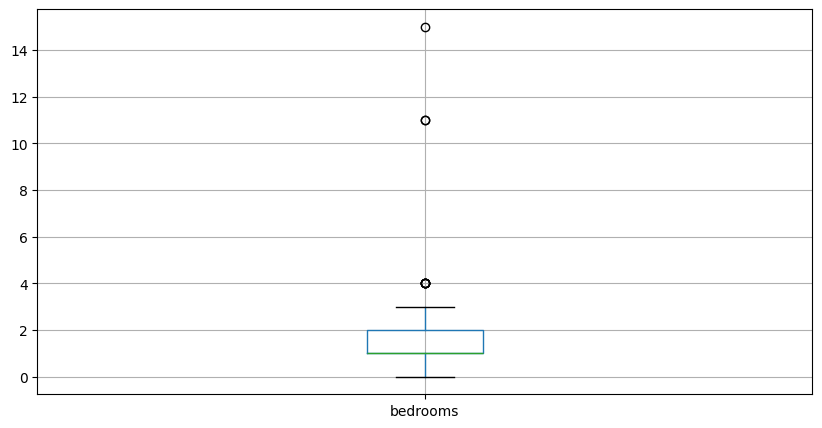

In [ ]:
#Aquí notamos que hay propiedades con 15, 11 y 4 habitaciones que son valores atípicos.
ax = df.boxplot(column=['bedrooms'], figsize=(10, 5))

In [ ]:
#Filtramos la base para quedarnos con las propiedades con 1, 2 o 3 habitaciones.
df = df[(df['bedrooms'] < 4) & (df['bedrooms'] > 0) | (df["bedrooms"].isna())]

<Axes: >

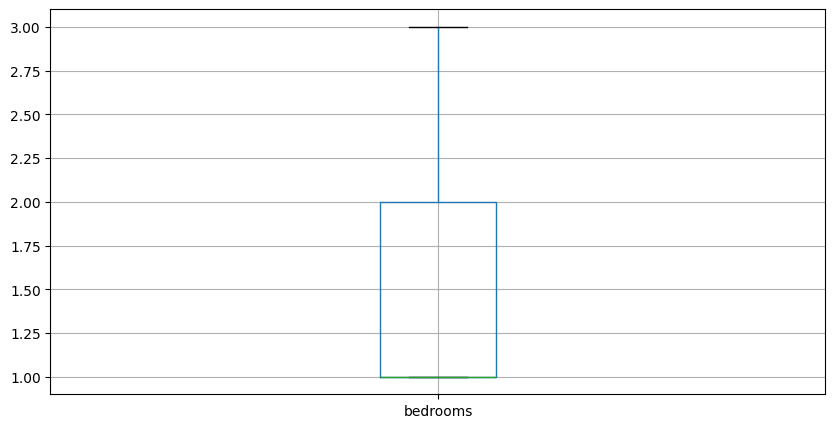

In [ ]:
df.boxplot(column=['bedrooms'], figsize=(10, 5))

In [ ]:
df['rooms'].describe()

,rooms
count,77324.000000
mean,2.099762
std,0.773650
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,3.000000


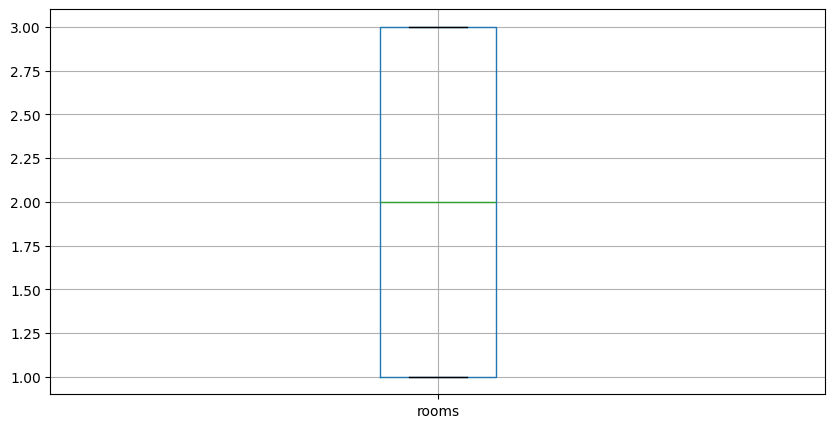

In [ ]:
ax = df.boxplot(column=['rooms'], figsize=(10, 5))

In [ ]:
df['bathrooms'].describe()

,bathrooms
count,74500.000000
mean,1.217826
std,0.486894
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,20.000000


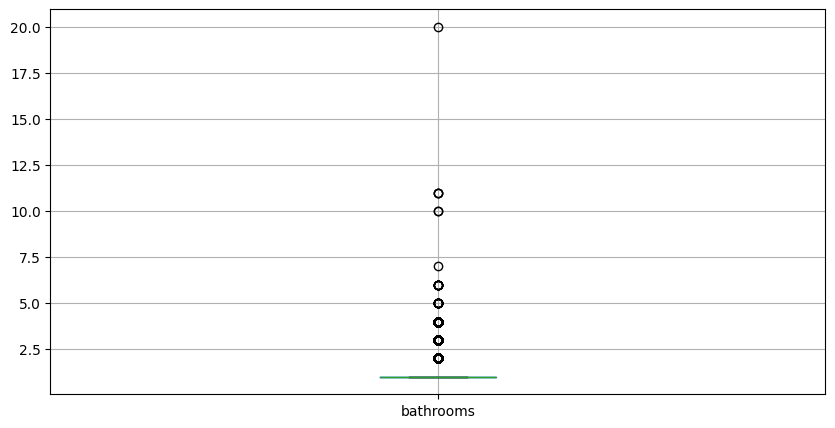

In [ ]:
#También vemos valores atípicos en algunas propiedades con respecto a la cantidad de baños.
ax = df.boxplot(column=['bathrooms'], figsize=(10, 5))

In [ ]:
#Filtramos la base para quedarnos con las propiedades con 1, 2 o 3 habitaciones.
df = df[(df['bathrooms'] < 4) & (df['bathrooms'] > 0) | (df["bathrooms"].isna())]

<Axes: >

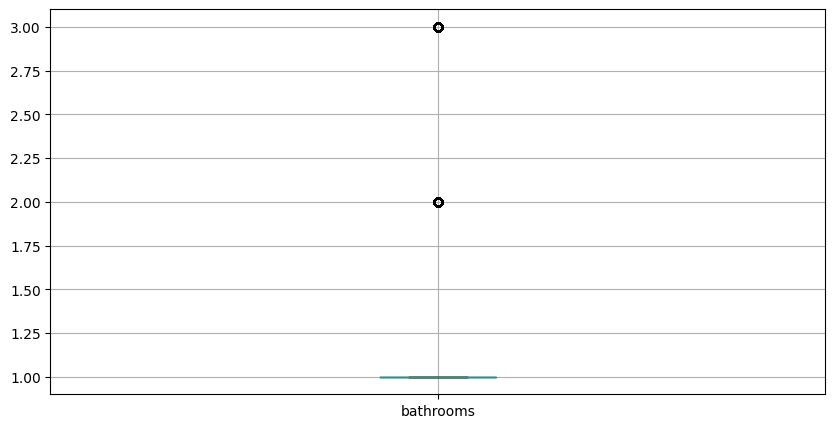

In [ ]:
df.boxplot(column=['bathrooms'], figsize=(10, 5))

In [ ]:
df['surface_total'].describe()

,surface_total
count,63041.000000
mean,71.016640
std,611.357748
min,10.000000
25%,40.000000
50%,52.000000
75%,70.000000
max,108960.000000


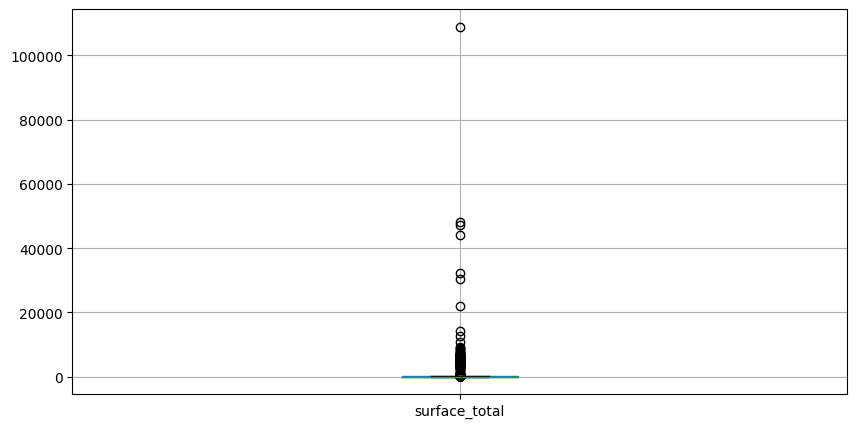

In [ ]:
ax = df.boxplot(column=['surface_total'], figsize=(10, 5))

In [ ]:
df["surface_total"].quantile(0.95)

np.float64(108.0)

In [ ]:
df["surface_total"].quantile(0.05)

np.float64(30.0)

In [ ]:
#En el código anterior vimos que el 99% de los datos se encuentran por debajo de 167.
#Además, el 1% de los valores están por debajo de 23.
#Luego,  filtramos la base para quedarnos con los valores entre 23 y 167.
df = df[(df['surface_total']<=df["surface_total"].quantile(0.95)) & (df['surface_total']>=df["surface_total"].quantile(0.05)) | (df["surface_total"].isna())]

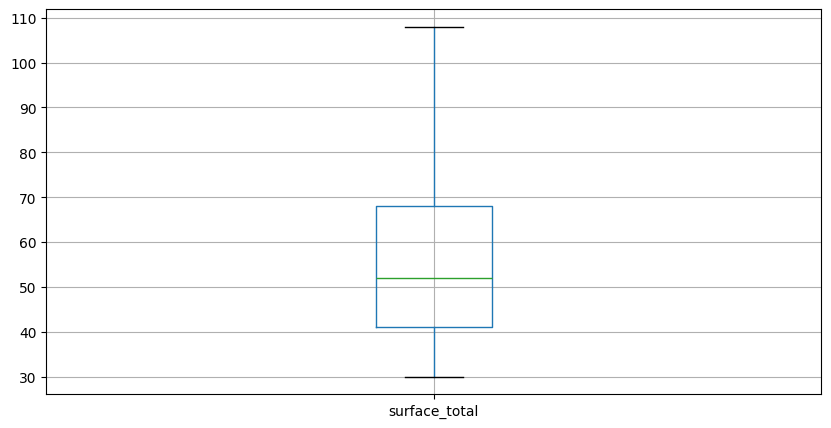

In [ ]:
ax = df.boxplot(column=['surface_total'], figsize=(10, 5))

In [ ]:
df['surface_covered'].describe()

,surface_covered
count,58467.000000
mean,51.205603
std,76.168203
min,1.000000
25%,37.000000
50%,46.000000
75%,60.000000
max,7120.000000


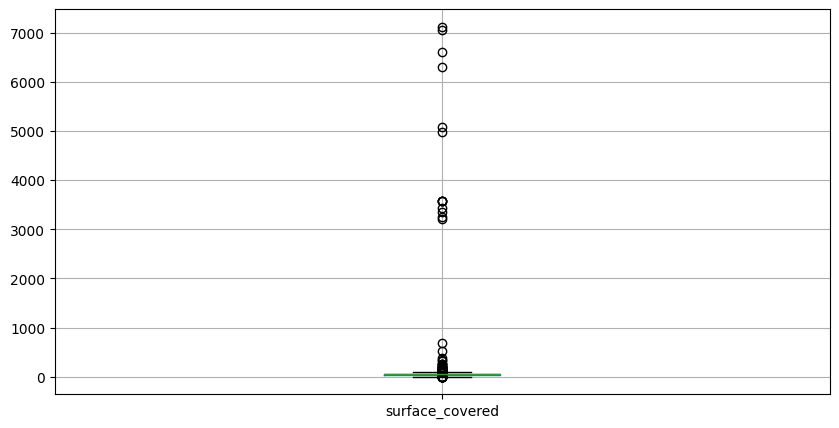

In [ ]:
#Trabajaremos de manera análoga a surface_total
ax = df.boxplot(column=['surface_covered'], figsize=(10, 5))

In [ ]:
df['surface_covered'].quantile(0.95)

np.float64(81.0)

In [ ]:
df['surface_covered'].quantile(0.05)

np.float64(30.0)

In [ ]:
#Filtramos la base para quedarnos con los valores entre 24 y 118.
df = df[(df['surface_covered']<=df["surface_covered"].quantile(0.95)) & (df['surface_covered']>=df["surface_covered"].quantile(0.05)) | (df["surface_covered"].isna())]

<Axes: >

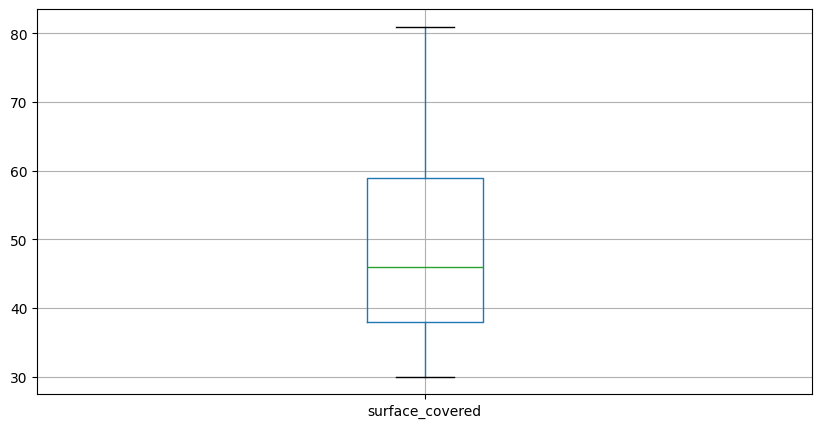

In [ ]:
df.boxplot(column=['surface_covered'], figsize=(10, 5))

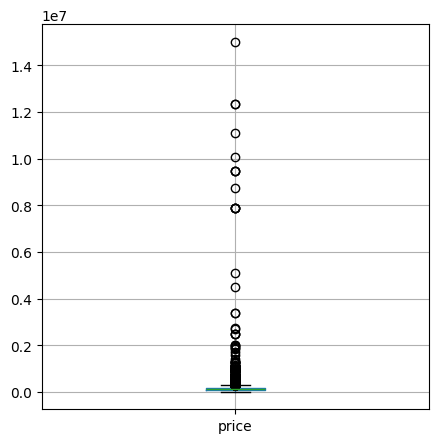

In [ ]:
ax = df.boxplot(column=['price'], figsize=(5, 5)) #Notamos que hay varios outliers en el precio.

In [ ]:
df['price'].describe()

,price
count,6.617200e+04
mean,1.533707e+05
std,1.648408e+05
min,9.500000e+03
25%,1.016472e+05
50%,1.350000e+05
75%,1.800000e+05
max,1.501116e+07


In [ ]:
df['price'].quantile(0.05)

np.float64(71401.0)

In [ ]:
df['price'].quantile(0.95)

np.float64(280000.0)

In [ ]:
p01 = df["price"].quantile(0.01)
p99 = df["price"].quantile(0.99)

df = df[(df["price"] >= p01) & (df["price"] <= p99) | (df["price"].isna())]

<Axes: >

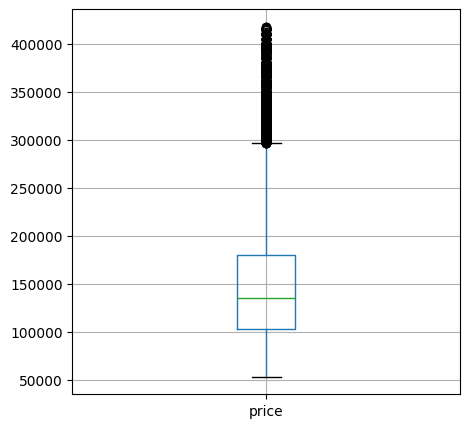

In [ ]:
df.boxplot(column=['price'], figsize=(5, 5))

In [ ]:
mask = df["surface_covered"] > df["surface_total"]
df[mask]

,id,lat,lon,l1,l2,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,currency,title,description,property_type,operation_type,price,ratio_cubierto,rooms_per_m2,bath_per_room
13,438415,-58.398942,-34.606149,Argentina,Capital Federal,Balvanera,2.0,1.0,1.0,32.0,33.0,USD,Departamento 2 ambientes. Cocina separada. Ba...,Corredor Responsable: BEATRIZ ALFONSIN - CUCIC...,Departamento,Venta,69000.0,1.031250,0.062500,0.500000
641,219825,-58.502862,-34.621034,Argentina,Capital Federal,Villa Devoto,3.0,2.0,1.0,54.0,55.0,USD,VENTA DE DPTO. PISO 3 AMB. A ESTRENAR,Corredor Responsable: CARLOS ALARCON - CPI 505...,Departamento,Venta,137000.0,1.018519,0.055556,0.333333
649,747468,-58.389244,-34.607268,Argentina,Capital Federal,Congreso,3.0,2.0,1.0,76.0,77.0,USD,Amplio Piso 3 ambientes al frente muy luminoso,Corredor Responsable: BEATRIZ ALFONSIN - CUCIC...,Departamento,Venta,145000.0,1.013158,0.039474,0.333333
1600,95756,-58.467620,-34.544764,Argentina,Capital Federal,Nuñez,2.0,1.0,1.0,30.0,31.0,USD,VENTA DEPARTAMENTO 2 AMBIENTES NUÑEZ,Corredor Responsable: Gustavo Guastello - C.U....,Departamento,Venta,84000.0,1.033333,0.066667,0.500000
1960,638567,-58.495567,-34.626993,Argentina,Capital Federal,Velez Sarsfield,2.0,1.0,1.0,42.0,43.0,USD,Departamento 2 Ambientes Velez Sarsfield,Corredor Responsable: Ariel Champanier - CUCIC...,Departamento,Venta,72000.0,1.023810,0.047619,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
965180,964962,-58.456008,-34.566226,Argentina,Capital Federal,Belgrano,3.0,2.0,1.0,78.0,79.0,USD,VENTA 3 AMB CON DEPD. BELGRANO,Corredor Responsable: Gustavo Guastello - C.U....,Departamento,Venta,225000.0,1.012821,0.038462,0.333333
967918,967708,-58.402845,-34.608859,Argentina,Capital Federal,Balvanera,3.0,2.0,1.0,75.0,78.0,USD,VENTA DEPTO.3 AMB.C/DEP LAV. LUMINOSO BALVANERA,Corredor Responsable: Jorge Salafia - CUCICBA ...,Departamento,Venta,148000.0,1.040000,0.040000,0.333333
973934,973741,-58.387871,-34.597175,Argentina,Capital Federal,Recoleta,3.0,2.0,1.0,58.0,59.0,USD,3 ambientes Recoleta impecable,Corredor Responsable: Mauro Marvisi - CUCICBA ...,Departamento,Venta,159000.0,1.017241,0.051724,0.333333
973963,973770,-58.439237,-34.617899,Argentina,Capital Federal,Caballito,3.0,2.0,1.0,70.0,71.0,USD,VENTA DEPARTAMENTO 3 AMBIENTES CABALLITO MUY L...,Corredor Responsable: Raul Hector Merlo - CUCI...,Departamento,Venta,135000.0,1.014286,0.042857,0.333333


In [ ]:
df.loc[mask, ["surface_covered", "surface_total"]] = \
df.loc[mask, ["surface_total", "surface_covered"]].values

In [ ]:
df.shape

(64903, 20)

##Histograma y Diagrama de barras

In [ ]:
import matplotlib.pyplot as plt

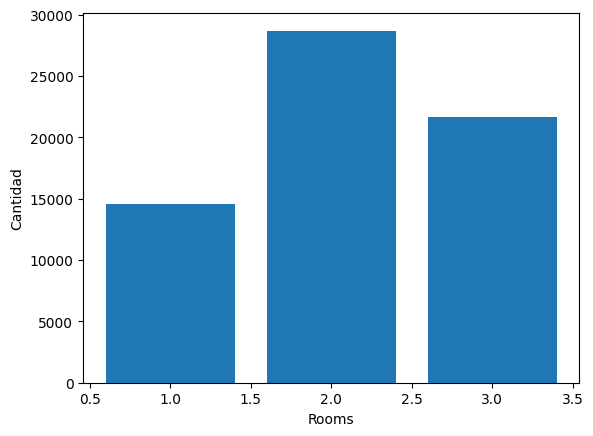

In [ ]:
conteo = df["rooms"].value_counts().sort_index()

plt.bar(conteo.index, conteo.values)
plt.xlabel("Rooms")
plt.ylabel("Cantidad")
plt.show()

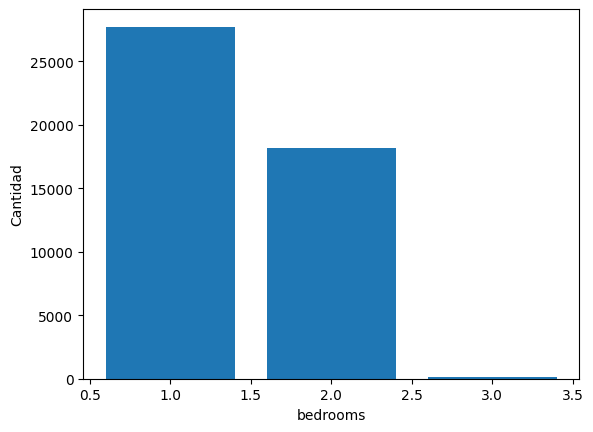

In [ ]:
conteo = df["bedrooms"].value_counts().sort_index()

plt.bar(conteo.index, conteo.values)
plt.xlabel("bedrooms")
plt.ylabel("Cantidad")
plt.show()

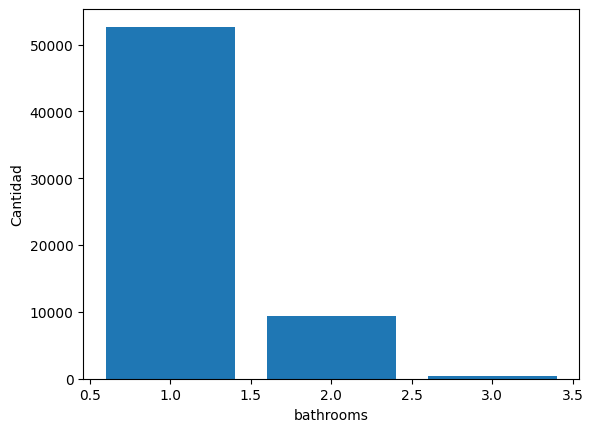

In [ ]:
conteo = df["bathrooms"].value_counts().sort_index()

plt.bar(conteo.index, conteo.values)
plt.xlabel("bathrooms")
plt.ylabel("Cantidad")
plt.show()

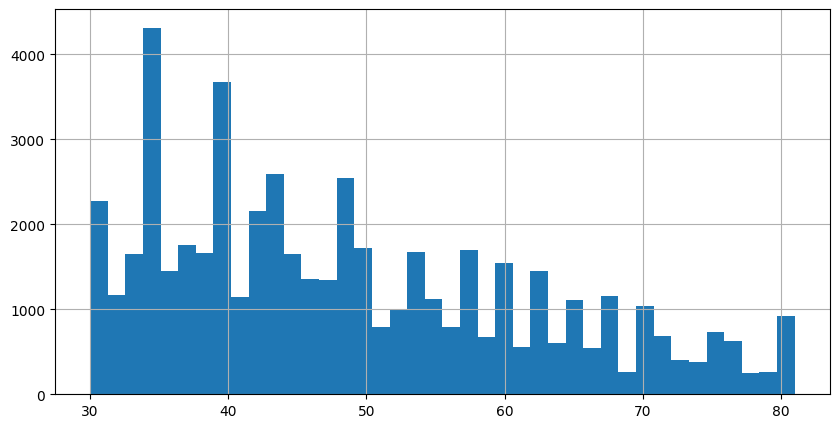

In [ ]:
ax = df['surface_covered'].hist(figsize=(10, 5), bins=40)

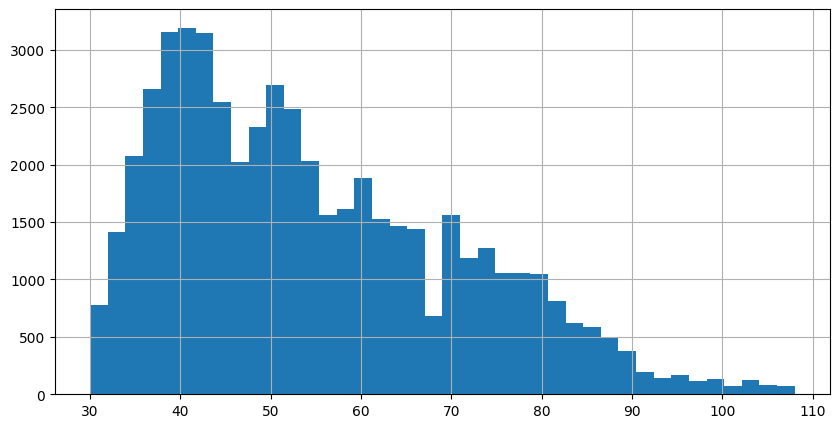

In [ ]:
ax = df['surface_total'].hist(figsize=(10, 5), bins=40)

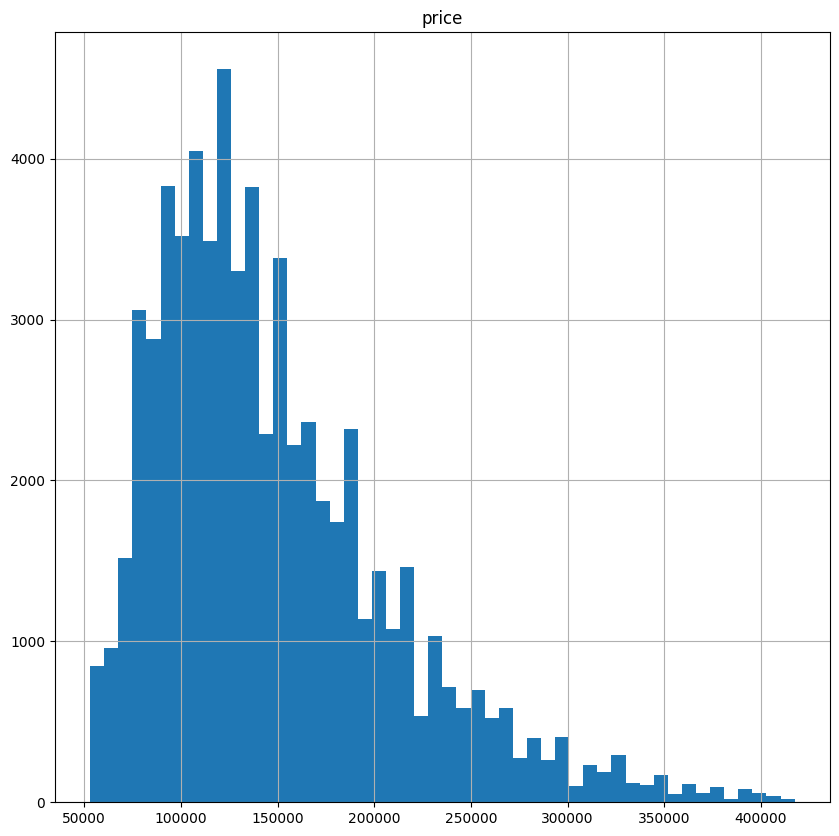

In [ ]:
ax = df.hist(column="price", bins=50, figsize=(10,10))

#Datos Faltantes

## Cantidad de valores faltantes por variable

In [ ]:
df.shape

(64903, 20)

La cantidad de registros, luego de filtrar y tratar los outliers, es de 64903. Ahora trabajaremos con los datos faltantes de cada variable.

In [ ]:
df_copy2 = df.copy()

In [ ]:
#Veamos la cantidad de elementos vacíos en cada atributo.
df.isna().sum()

,0
id,0
lat,5005
lon,4962
l1,0
l2,0
l3,2661
rooms,0
bedrooms,18920
bathrooms,2512
surface_total,13016


In [ ]:
df["lat"] = df["lat"].fillna(
    df.groupby("l3")["lat"].transform("median")
)

df["lon"] = df["lon"].fillna(
    df.groupby("l3")["lon"].transform("median")
)

In [ ]:
df["lat"] = df["lat"].fillna(
    df.groupby("l2")["lat"].transform("median")
)

df["lon"] = df["lon"].fillna(
    df.groupby("l2")["lon"].transform("median")
)

In [ ]:
#Notemos que varias de las propiedades que tienen valores faltantes en "l3" también lo tienen en otros atributos.
#Es por este motivo que se decidió eliminar esos registros.
df_copy2[df_copy2['l3'].isna()]

,id,lat,lon,l1,l2,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,currency,title,description,property_type,operation_type,price,ratio_cubierto,rooms_per_m2,bath_per_room
19,801187,NaN,NaN,Argentina,Capital Federal,NaN,2.0,1.0,1.0,NaN,NaN,USD,1 dormitorio - Pichincha ROSARIO,Venta departamento de 1 dormitorio \n\nUbicaci...,Departamento,Venta,84500.0,NaN,NaN,0.500000
92,395266,NaN,NaN,Argentina,Capital Federal,NaN,2.0,1.0,1.0,NaN,NaN,USD,Venta departamento de 2 ambientes en el Centro...,Luminoso y muy buen estado!!!\nExcelente depar...,Departamento,Venta,58000.0,NaN,NaN,0.500000
119,352714,-60.628453,-32.952315,Argentina,Capital Federal,NaN,3.0,1.0,1.0,NaN,NaN,USD,DEPARTAMENTO A ESTRENAR 1 DORMITORIO CON BALCO...,Edificio SOL PATAGONIA XXII\n\nUbicaci&oacute...,Departamento,Venta,135200.0,NaN,NaN,0.333333
146,71525,NaN,NaN,Argentina,Capital Federal,NaN,2.0,1.0,1.0,NaN,NaN,USD,EN VENTA - CORRIENTES 336,Muy lindo Departamento en VENTA con Cochera.\n...,Departamento,Venta,75000.0,NaN,NaN,0.500000
158,210212,NaN,NaN,Argentina,Capital Federal,NaN,2.0,1.0,1.0,NaN,NaN,USD,DEPTO 2 AMB A LA CALLE ZONA ALDREY,a 1 cuadra del PASEO ALDREY nos encontramos co...,Departamento,Venta,75000.0,NaN,NaN,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
998738,998739,NaN,NaN,Argentina,Capital Federal,NaN,2.0,1.0,2.0,NaN,NaN,USD,Playa Chica. Departamento de Categoría 2 Ambie...,En el edificio de categor&iacute;a Maral 51 ub...,Departamento,Venta,250000.0,NaN,NaN,1.000000
998740,998741,NaN,NaN,Argentina,Capital Federal,NaN,3.0,2.0,2.0,NaN,NaN,USD,PISO 3 AMB con COCHERA en LA PERLA,"DEPARTAMENTO 3 AMB en piso completo, 7&deg; a ...",Departamento,Venta,165000.0,NaN,NaN,0.666667
998741,998742,NaN,NaN,Argentina,Capital Federal,NaN,3.0,2.0,2.0,NaN,NaN,USD,Departamento 3 amb con dependencia/ A la calle...,Departamento 3 amb dentro de galeria. A la cal...,Departamento,Venta,85000.0,NaN,NaN,0.666667
998742,998743,NaN,NaN,Argentina,Capital Federal,NaN,3.0,1.0,2.0,NaN,NaN,USD,DEPARTAMENTO 2 AMB + ESCRITORIO al FRENTE con ...,DEPARTAMENTO 2 AMB + ESCRITORIO al FRENTE con ...,Departamento,Venta,135000.0,NaN,NaN,0.666667


In [ ]:
df = df.dropna(subset=['l3'])

In [ ]:
df.isna().sum()

,0
id,0
lat,0
lon,0
l1,0
l2,0
l3,0
rooms,0
bedrooms,18408
bathrooms,2228
surface_total,10446


In [ ]:
#Veamos si hay datos duplicados.
df.duplicated().sum()

np.int64(0)

In [ ]:
#Veamos la asimetría de cada variable, para ver si rellenamos con la media o la mediana.

In [ ]:
df.skew(numeric_only=True)

,0
id,0.201026
lat,-0.229170
lon,142.118690
rooms,-0.178468
bedrooms,0.447681
bathrooms,2.169374
surface_total,0.682375
surface_covered,0.600214
price,1.199028
ratio_cubierto,-1.679161


In [ ]:
#En las variables cuya asimetría fue menor a 0.5 usaremos la media, mientras que en el resto se utilizará la mediana.
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].mean())
df["rooms_per_m2"] = df["rooms_per_m2"].fillna(df["rooms_per_m2"].mean())

In [ ]:
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median())
df["surface_total"] = df["surface_total"].fillna(df["surface_total"].median())
df["surface_covered"] = df["surface_covered"].fillna(df["surface_covered"].median())
df["ratio_cubierto"] = df["ratio_cubierto"].fillna(df["ratio_cubierto"].median())
df["bath_per_room"] = df["bath_per_room"].fillna(df["bath_per_room"].median())

In [ ]:
df.isna().sum()

,0
id,0
lat,0
lon,0
l1,0
l2,0
l3,0
rooms,0
bedrooms,0
bathrooms,0
surface_total,0


In [ ]:
df

,id,lat,lon,l1,l2,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,currency,title,description,property_type,operation_type,price,ratio_cubierto,rooms_per_m2,bath_per_room
0,556713,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,3.0,2.000000,2.0,51.0,46.0,USD,"Departamento en Venta en Belgrano, Capital fed...","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0,0.918919,0.038665,0.666667
1,192912,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,3.0,2.000000,2.0,77.0,67.0,USD,Departamento de 3 ambientes en Venta en Almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0,0.870130,0.038961,0.666667
2,238224,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,2.0,1.402952,1.0,60.0,55.0,USD,Andonaegui 2600 4° - - Departamento en Venta,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0,0.916667,0.033333,0.500000
4,521738,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,3.0,2.000000,1.0,66.0,64.0,USD,Venta 3 Ambientes - Almagro - Balcón - Ameniti...,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0,0.969697,0.045455,0.333333
8,76927,-58.507339,-34.590882,Argentina,Capital Federal,Villa Devoto,2.0,1.402952,2.0,51.0,46.0,USD,Departamento en Venta ubicado en Villa Devoto...,"Forma de pago: 35% de anticipo, saldo en cuota...",Departamento,Venta,159900.0,0.918919,0.038665,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,997856,-58.432878,-34.570112,Argentina,Capital Federal,Las Cañitas,2.0,1.000000,2.0,73.0,65.0,USD,ARCE AL 500- CAÑITAS -HERMOSÍSIMO DEPTO!! Sùp...,Operación: venta Intersección de calles: Orteg...,Departamento,Venta,380000.0,0.890411,0.027397,1.000000
997856,997857,-58.432878,-34.570112,Argentina,Capital Federal,Las Cañitas,2.0,1.000000,2.0,73.0,65.0,USD,ARCE AL 500- CAÑITAS -HERMOSÍSIMO DEPTO!! Sùp...,Operación: venta Intersección de calles: Orteg...,Departamento,Venta,360000.0,0.890411,0.027397,1.000000
997863,997864,-58.435634,-34.606500,Argentina,Capital Federal,Parque Centenario,3.0,2.000000,2.0,61.0,59.0,USD,Excepc 3 amb fte c/bcon aterraz 10 años c/2 ba...,Hermoso 3 ambientes al frente con balcón aterr...,Departamento,Venta,160000.0,0.967213,0.049180,0.666667
998754,998755,-58.473996,-34.634941,Argentina,Capital Federal,Floresta,3.0,2.000000,2.0,74.0,67.0,USD,"VENTA DEPTO 3 AMB. AL FRENTE ""SUPER LUMINOSO"" ...","VENTA DEPARTAMENTO 3 AMBIENTE 74M2 TOTALES ""SU...",Departamento,Venta,170000.0,0.905405,0.040541,0.666667


In [ ]:
df.shape

(62242, 20)

In [ ]:
df.isna().sum()

,0
id,0
lat,0
lon,0
l1,0
l2,0
l3,0
rooms,0
bedrooms,0
bathrooms,0
surface_total,0


In [ ]:
df = df.dropna(subset=['title'])

In [ ]:
df.shape

(62236, 20)

#Modelos de Aprendizaje Automático

In [ ]:
df_copy3=df.copy()

In [ ]:
df_copy4=df_copy3.select_dtypes(include='number')

In [ ]:
X = df_copy4[df_copy4.columns.drop("price")]
y = df_copy4["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.shape, X_train.shape, X_test.shape

((62236, 11), (49788, 11), (12448, 11))

## Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error


rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
import numpy as np
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  620,037,423.32
RMSE: 24,900.55


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.16632296646566863)

En este caso, se ve un 16.6% de error aproximadamente en el modelo Random Forest

##KNN

In [ ]:
pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=5, weights='uniform', p=2))
])

pipeline_knn.fit(X_train, y_train)

y_pred_knn = pipeline_knn.predict(X_test)

mse = sk.metrics.mean_squared_error(y_test, y_pred_knn)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"RMSE/Media: {rmse/y_test.mean()*100:.1f}%")

MSE:  1,504,076,488.24
RMSE: 38,782.42
RMSE/Media: 25.9%


En el modelo KNN se puede observar un error relativo del 26%.

##Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

modelo_gb = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=7,
    subsample=0.8,
    random_state=42
)

modelo_gb.fit(X_train, y_train)

y_pred_gb = modelo_gb.predict(X_test)

mse = sk.metrics.mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"RMSE/Media: {rmse/y_test.mean()*100:.1f}%")

MSE:  683,637,417.54
RMSE: 26,146.46
RMSE/Media: 17.5%


# Optimización de Hiperparámetros y Validación Cruzada

In [ ]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'knn__n_neighbors': [3, 5, 7, 10, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]  # 1=Manhattan, 2=Euclidiana
}

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

search.fit(X_train, y_train)

print(search.best_params_)

{'knn__weights': 'distance', 'knn__p': 1, 'knn__n_neighbors': 15}


In [ ]:
rf = RandomForestRegressor(random_state=42)

param_dist_rf = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
}

rf_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist_rf,
    n_iter=15,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train, y_train)

print("Mejores parámetros RF:", rf_search.best_params_)
print("Mejor score RF:", rf_search.best_score_)

best_rf = rf_search.best_estimator_

/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Mejores parámetros RF: {'n_estimators': 500, 'max_depth': None}
Mejor score RF: -625387143.3644347


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(random_state=42)

param_dist_gb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.7, 0.8, 1.0]
}

gb_search = RandomizedSearchCV(
    gb,
    param_distributions=param_dist_gb,
    n_iter=15,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

gb_search.fit(X_train, y_train)

print("Mejores parámetros GB:", gb_search.best_params_)
print("Mejor score GB:", gb_search.best_score_)

best_gb = gb_search.best_estimator_

Mejores parámetros GB: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.1}
Mejor score GB: -703651410.6191194


# Evaluación de modelos con los hiperparámetros optimizados

##Random Forest

In [ ]:
rf = RandomForestRegressor(n_estimators=500, max_depth=None, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
error_rf/y_test.mean()

np.float64(0.1661868411217222)

In [ ]:
y_pred_rf = rf.predict(X_test)
mse = sk.metrics.mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"RMSE/Media: {rmse/y_test.mean()*100:.1f}%")

MSE:  619,022,911.97
RMSE: 24,880.17
RMSE/Media: 16.6%


## KNN

In [ ]:
pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=15, weights='distance', p=1))
])

pipeline_knn.fit(X_train, y_train)

y_pred_knn = pipeline_knn.predict(X_test)

mse = sk.metrics.mean_squared_error(y_test, y_pred_knn)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"RMSE/Media: {rmse/y_test.mean()*100:.1f}%")

MSE:  1,117,157,801.97
RMSE: 33,423.91
RMSE/Media: 22.3%


##Gradient Boosting

In [ ]:
modelo_gb = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=7,
    subsample=0.8,
    random_state=42
)

modelo_gb.fit(X_train, y_train)

y_pred_gb = modelo_gb.predict(X_test)

mse = sk.metrics.mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"RMSE/Media: {rmse/y_test.mean()*100:.1f}%")

MSE:  683,637,417.54
RMSE: 26,146.46
RMSE/Media: 17.5%


#Gráfico de importancias de los atributos

       Atributo  Importancia
  surface_total     0.346014
            lon     0.210272
            lat     0.146473
      bathrooms     0.112686
             id     0.043277
surface_covered     0.042953
 ratio_cubierto     0.034800
   rooms_per_m2     0.032126
          rooms     0.015909
       bedrooms     0.009100
  bath_per_room     0.006389


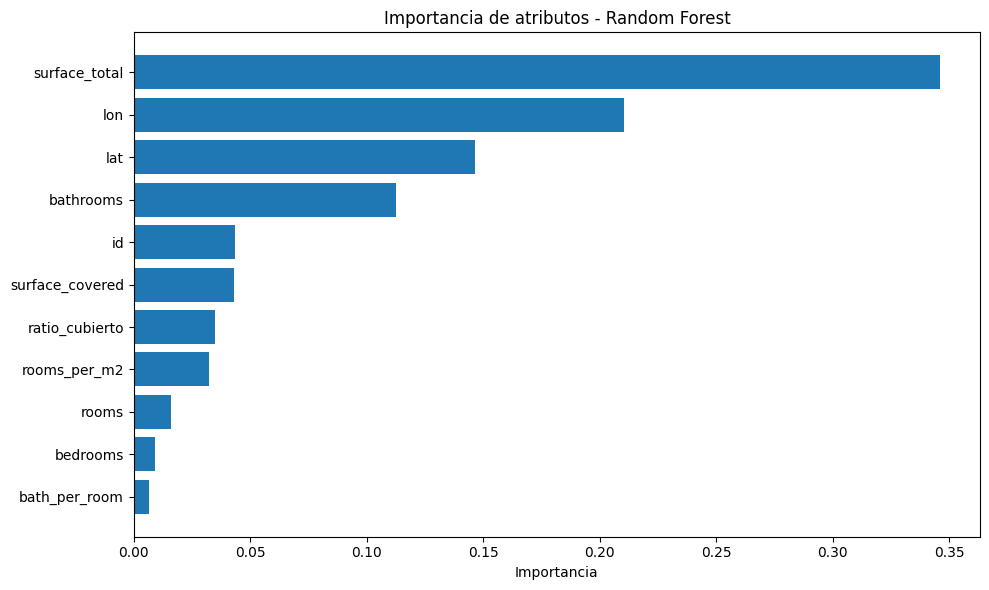

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importancias_rf = rf_search.best_estimator_.feature_importances_
features = X_train.columns

df_imp_rf = pd.DataFrame({'Atributo': features, 'Importancia': importancias_rf})
df_imp_rf = df_imp_rf.sort_values('Importancia', ascending=False)

print(df_imp_rf.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(df_imp_rf['Atributo'], df_imp_rf['Importancia'])
plt.xlabel('Importancia')
plt.title('Importancia de atributos - Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Random Forest (title)

En el trabajo anterior, Random Forest fue el que menor RMSE tuvo. Veamos cómo afecta este RMSE al aplicar los conceptos de minería de datos.

In [ ]:
df_copy1 = df.copy()

In [ ]:
df_copy2=df_copy1.select_dtypes(include='number')

## Sin tratar texto

In [ ]:
X = df_copy2[df_copy2.columns.drop("price")]
y = df_copy2["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.shape, X_train.shape, X_test.shape

((62236, 11), (49788, 11), (12448, 11))

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
import numpy as np
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  620,037,423.32
RMSE: 24,900.55


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.16632296646566863)

## Minúsculas y tokenizar title

In [ ]:
df['title'] = df['title'].str.lower()
df.head()

/tmp/ipykernel_2303/4288255960.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title'] = df['title'].str.lower()


,id,lat,lon,l1,l2,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,currency,title,description,property_type,operation_type,price,ratio_cubierto,rooms_per_m2,bath_per_room
0,556713,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,3.0,2.000000,2.0,51.0,46.0,USD,"departamento en venta en belgrano, capital fed...","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0,0.918919,0.038665,0.666667
1,192912,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,3.0,2.000000,2.0,77.0,67.0,USD,departamento de 3 ambientes en venta en almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0,0.870130,0.038961,0.666667
2,238224,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,2.0,1.402952,1.0,60.0,55.0,USD,andonaegui 2600 4° - - departamento en venta,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0,0.916667,0.033333,0.500000
4,521738,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,3.0,2.000000,1.0,66.0,64.0,USD,venta 3 ambientes - almagro - balcón - ameniti...,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0,0.969697,0.045455,0.333333
8,76927,-58.507339,-34.590882,Argentina,Capital Federal,Villa Devoto,2.0,1.402952,2.0,51.0,46.0,USD,departamento en venta ubicado en villa devoto...,"Forma de pago: 35% de anticipo, saldo en cuota...",Departamento,Venta,159900.0,0.918919,0.038665,1.000000


In [ ]:
import spacy

import locale
locale.getpreferredencoding = lambda: "UTF-8"

In [ ]:
! spacy download es_core_news_sm --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 85.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
nlp = spacy.load("es_core_news_sm")

In [ ]:
doc = nlp(df.iloc[3].title)
print(doc.text)

for token in doc:
    print(token.text, token.pos_)

venta 3 ambientes - almagro - balcón - amenities -
venta VERB
3 NUM
ambientes NOUN
- PUNCT
almagro NOUN
- PUNCT
balcón NOUN
- PUNCT
amenities NOUN
- PUNCT


In [ ]:
palabras = set()

for texto in df['title'].values:
    for token in nlp(texto):
        palabras.add(token.text)

len(palabras)

8791

In [ ]:
df['title_tok'] = df['title'].apply(lambda texto: [token.text for token in nlp(texto)])
df['title_tok']

/tmp/ipykernel_2303/3052519026.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title_tok'] = df['title'].apply(lambda texto: [token.text for token in nlp(texto)])


,title_tok
0,"[departamento, en, venta, en, belgrano, ,, cap..."
1,"[departamento, de, 3, ambientes, en, venta, en..."
2,"[andonaegui, , 2600, 4, °, , -, , -, depar..."
4,"[venta, 3, ambientes, -, almagro, -, balcón, -..."
8,"[departamento, , en, venta, ubicado, en, vill..."
...,...
997855,"[ , arce, al, 500-, cañitas, -hermosísimo, dep..."
997856,"[ , arce, al, 500-, cañitas, -hermosísimo, dep..."
997863,"[excepc, 3, amb, fte, c, /, bcon, aterraz, 10,..."
998754,"[venta, depto, 3, amb, ., al, frente, "", super..."


Vectorizer

In [ ]:
df['title'] = df['title_tok'].str.join(' ')
df['title']

/tmp/ipykernel_2303/941007135.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title'] = df['title_tok'].str.join(' ')


,title
0,"departamento en venta en belgrano , capital fe..."
1,departamento de 3 ambientes en venta en almagro
2,andonaegui 2600 4 ° - - departamento en...
4,venta 3 ambientes - almagro - balcón - ameniti...
8,departamento en venta ubicado en villa devot...
...,...
997855,arce al 500- cañitas -hermosísimo depto ! ! ...
997856,arce al 500- cañitas -hermosísimo depto ! ! ...
997863,excepc 3 amb fte c / bcon aterraz 10 años c/2 ...
998754,"venta depto 3 amb . al frente "" super luminoso..."


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(ngram_range=(1, 3), min_df=0.01, max_df=0.7, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title'])

In [ ]:
vectorized_data.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
vectorizer.get_feature_names_out()

array(['000', '000 departamento', '000 departamento en', 'al',
       'al frente', 'almagro', 'alto', 'amb', 'amb con', 'amb en',
       'ambiente', 'ambiente en', 'ambiente en venta', 'ambientes',
       'ambientes con', 'ambientes con balcon', 'ambientes con cochera',
       'ambientes en', 'ambientes en venta', 'ambientes estrenar',
       'amenities', 'amplio', 'apto', 'apto profesional', 'av', 'balcon',
       'balvanera', 'barrio', 'barrio norte', 'baulera', 'belgrano',
       'caballito', 'capital', 'capital federal', 'centenario', 'cochera',
       'colegiales', 'con', 'con balcon', 'con cochera', 'con patio',
       'crespo', 'cristobal', 'de', 'de ambiente', 'de ambiente en',
       'de ambientes', 'de ambientes en', 'del', 'departamento',
       'departamento amb', 'departamento ambientes',
       'departamento ambientes con', 'departamento ambientes en',
       'departamento de', 'departamento de ambiente',
       'departamento de ambientes', 'departamento en',
       'depa

In [ ]:
count_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
#count_df.shape
#count_df
count_df.columns

Index(['000', '000 departamento', '000 departamento en', 'al', 'al frente',
       'almagro', 'alto', 'amb', 'amb con', 'amb en',
       ...
       'venta en almagro', 'venta en caballito', 'venta en palermo',
       'venta en parque', 'venta en villa', 'venta monoambiente', 'villa',
       'villa crespo', 'villa urquiza', 'vista'],
      dtype='object', length=142)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title'])

In [ ]:
vectorizer.get_feature_names_out()

array(['000', '000 amb', '000 apto', '000 departamento', '10', '100',
       '1000', '11', '110', '110 000', '1100', '115', '115000', '12',
       '120', '120 000', '1200', '125', '130', '1300', '1400', '145',
       '145 000', '150', '150 000', '1500', '1600', '1700', '1800',
       '1900', '1amb', '200', '2000', '2020', '2021', '2100', '2200',
       '2300', '2400', '24hs', '2500', '2600', '2700', '2800', '2900',
       '2amb', '300', '3000', '3100', '3200', '3300', '3400', '3500',
       '36', '3600', '37', '3700', '3800', '3amb', '40', '400', '4000',
       '4100', '4200', '4300', '4400', '4500', '4600', '50', '500',
       '500 departamento', '60', '600', '70', '700', '75', '80', '800',
       '85', '90', '900', '900 departamento', '95', 'abasto',
       'abasto capital', 'abierta', 'achala', 'achala 3500', 'al',
       'al 200', 'al 600', 'al 900', 'al contrafrente', 'al frente',
       'al fte', 'alberdi', 'almagro', 'almagro capital', 'almagro norte',
       'alquiler', 'alto',

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,000,000 amb,000 apto,000 departamento,10,100,1000,11,110,110 000,...,visitalo,vista,vista abierta,vista al,vista panoramica,vivienda,vta,zencity,zona,zona de
0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.259959,0.304856,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997856,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.259959,0.304856,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997863,0.0,0.0,0.0,0.0,0.345996,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998754,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Aplicamos el modelo:

In [ ]:
df_completo = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy3 = df.copy()
df_copy4 = df_completo.copy()
df_copy4 = df_copy4.select_dtypes(include='number')

X = df_copy4[df_copy4.columns.drop("price")]
y = df_copy4["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.shape, X_train.shape, X_test.shape

((62236, 892), (49788, 892), (12448, 892))

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  587,652,988.52
RMSE: 24,241.55


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.16192121181956126)

## Filtrando stopwords

In [ ]:
stopwords = nlp.Defaults.stop_words
stopwords

{'a',
 'acuerdo',
 'adelante',
 'ademas',
 'además',
 'afirmó',
 'agregó',
 'ahi',
 'ahora',
 'ahí',
 'al',
 'algo',
 'alguna',
 'algunas',
 'alguno',
 'algunos',
 'algún',
 'alli',
 'allí',
 'alrededor',
 'ambos',
 'ante',
 'anterior',
 'antes',
 'apenas',
 'aproximadamente',
 'aquel',
 'aquella',
 'aquellas',
 'aquello',
 'aquellos',
 'aqui',
 'aquél',
 'aquélla',
 'aquéllas',
 'aquéllos',
 'aquí',
 'arriba',
 'aseguró',
 'asi',
 'así',
 'atras',
 'aun',
 'aunque',
 'añadió',
 'aún',
 'bajo',
 'bastante',
 'bien',
 'breve',
 'buen',
 'buena',
 'buenas',
 'bueno',
 'buenos',
 'cada',
 'casi',
 'cierta',
 'ciertas',
 'cierto',
 'ciertos',
 'cinco',
 'claro',
 'comentó',
 'como',
 'con',
 'conmigo',
 'conocer',
 'conseguimos',
 'conseguir',
 'considera',
 'consideró',
 'consigo',
 'consigue',
 'consiguen',
 'consigues',
 'contigo',
 'contra',
 'creo',
 'cual',
 'cuales',
 'cualquier',
 'cuando',
 'cuanta',
 'cuantas',
 'cuanto',
 'cuantos',
 'cuatro',
 'cuenta',
 'cuál',
 'cuáles',
 'cu

In [ ]:
stopwords.update(['es', 'sólo', 'la', 'el', 'los', 'las'])

df['title_tok'] = df['title_tok'].apply(lambda texto: [token for token in texto if token not in stopwords])
df['title_tok']

/tmp/ipykernel_2303/2798002193.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title_tok'] = df['title_tok'].apply(lambda texto: [token for token in texto if token not in stopwords])


,title_tok
0,"[departamento, venta, belgrano, ,, capital, fe..."
1,"[departamento, 3, ambientes, venta, almagro]"
2,"[andonaegui, , 2600, 4, °, , -, , -, depar..."
4,"[venta, 3, ambientes, -, almagro, -, balcón, -..."
8,"[departamento, , venta, ubicado, villa, devot..."
...,...
997855,"[ , arce, 500-, cañitas, -hermosísimo, depto, ..."
997856,"[ , arce, 500-, cañitas, -hermosísimo, depto, ..."
997863,"[excepc, 3, amb, fte, c, /, bcon, aterraz, 10,..."
998754,"[venta, depto, 3, amb, ., frente, "", super, lu..."


In [ ]:
df['title'] = df['title_tok'].str.join(' ')
df['title']

/tmp/ipykernel_2303/941007135.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title'] = df['title_tok'].str.join(' ')


,title
0,"departamento venta belgrano , capital federal"
1,departamento 3 ambientes venta almagro
2,andonaegui 2600 4 ° - - departamento venta
4,venta 3 ambientes - almagro - balcón - ameniti...
8,"departamento venta ubicado villa devoto , ca..."
...,...
997855,arce 500- cañitas -hermosísimo depto ! ! sùp...
997856,arce 500- cañitas -hermosísimo depto ! ! sùp...
997863,excepc 3 amb fte c / bcon aterraz 10 años c/2 ...
998754,"venta depto 3 amb . frente "" super luminoso "" ..."


In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title'])

In [ ]:
vectorizer.get_feature_names_out()

array(['000', '000 amb', '000 apto', '000 departamento', '10', '100',
       '1000', '11', '110', '110 000', '1100', '115', '115000', '12',
       '120', '120 000', '1200', '125', '130', '1300', '1400', '145',
       '145 000', '150', '150 000', '1500', '1600', '1700', '1800',
       '1900', '1amb', '200', '2000', '2020', '2021', '2100', '2200',
       '2300', '2400', '24hs', '2500', '2600', '2700', '2800', '2900',
       '2amb', '300', '3000', '3100', '3200', '3300', '3400', '3500',
       '36', '3600', '37', '3700', '3800', '3amb', '40', '400', '4000',
       '4100', '4200', '4300', '4400', '4500', '4600', '50', '500',
       '500 departamento', '60', '600', '70', '700', '75', '80', '800',
       '85', '90', '900', '900 departamento', '95', 'abasto',
       'abasto capital', 'abierta', 'achala', 'achala 3500', 'alberdi',
       'almagro', 'almagro ambientes', 'almagro capital', 'almagro norte',
       'alquiler', 'alto', 'alto palermo', 'alvarez', 'amb',
       'amb amenities', 'amb 

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,000,000 amb,000 apto,000 departamento,10,100,1000,11,110,110 000,...,villa urquiza,virrey,visitalo,vista,vista abierta,vista panoramica,vivienda,vta,zencity,zona
0,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.288229,0.338008,0.0,0.0,0.0,0.0,0.0
997856,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.288229,0.338008,0.0,0.0,0.0,0.0,0.0
997863,0.0,0.0,0.0,0.0,0.32647,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
998754,0.0,0.0,0.0,0.0,0.00000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


Random Forest

In [ ]:
df_modelo = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy5 = df_modelo.copy()
df_copy5 = df_copy5.select_dtypes(include='number')

X = df_copy5[df_copy5.columns.drop("price")]
y = df_copy5["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  580,343,112.30
RMSE: 24,090.31


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.16091098306525572)

## Lematización

In [ ]:
doc = nlp(df.iloc[4].title)
print(doc.text)
for token in doc:
    print(token.text, "-->", token.lemma_)

departamento   venta ubicado villa devoto , capital federal
departamento --> departamento
   -->   
venta --> ventar
ubicado --> ubicado
villa --> villa
devoto --> devoto
, --> ,
capital --> capital
federal --> federal


In [ ]:
lemas = set()

for texto in df['title'].values:
    for token in nlp(texto):
        lemas.add(token.lemma_)

len(lemas)

8554

In [ ]:
df['title_tok'] = df['title'].apply(lambda texto: [token.lemma_ for token in nlp(texto)])
df['title_tok']

/tmp/ipykernel_2303/1920892276.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title_tok'] = df['title'].apply(lambda texto: [token.lemma_ for token in nlp(texto)])


,title_tok
0,"[departamento, venta, belgrano, ,, capital, fe..."
1,"[departamento, 3, ambiente, ventar, almagro]"
2,"[andonaegui, , 2600, 4, °, , -, , -, de..."
4,"[ventar, 3, ambiente, -, almagro, -, balcón, -..."
8,"[departamento, , ventar, ubicado, villa, dev..."
...,...
997855,"[ , arcir, 500-, cañita, -hermosísimo, depto,..."
997856,"[ , arcir, 500-, cañita, -hermosísimo, depto,..."
997863,"[excepc, 3, amb, fte, c, /, bcon, aterraz, 10,..."
998754,"[ventar, depto, 3, amb, ., frente, "", super, l..."


In [ ]:
df['title'] = df['title_tok'].str.join(' ')
df['title']

/tmp/ipykernel_2303/941007135.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title'] = df['title_tok'].str.join(' ')


,title
0,"departamento venta belgrano , capital federal"
1,departamento 3 ambiente ventar almagro
2,andonaegui 2600 4 ° - - departamento...
4,ventar 3 ambiente - almagro - balcón - ameniti -
8,"departamento ventar ubicado villa devoto , ..."
...,...
997855,arcir 500- cañita -hermosísimo depto ! ! sù...
997856,arcir 500- cañita -hermosísimo depto ! ! sù...
997863,excepc 3 amb fte c / bcon aterraz 10 año c/2 b...
998754,"ventar depto 3 amb . frente "" super luminoso ""..."


In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title'])

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,000,000 apto,10,100,1000,105000,11,1100,110000,115000,...,visitalo,vista,vista abierto,vista panoramico,visto,visto abierto,vivienda,vta,zencity,zona
0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.294865,0.333356,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997856,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.294865,0.333356,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997863,0.0,0.0,0.325096,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998754,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Aplicamos Random Forest

In [ ]:
df_modelo1 = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy6 = df_modelo1.copy()
df_copy6 = df_copy6.select_dtypes(include='number')

X = df_copy6[df_copy6.columns.drop("price")]
y = df_copy6["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  583,762,912.22
RMSE: 24,161.19


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.16138438842558536)

## n-gramas (1,3)

In [ ]:
df['title'] = df['title_tok'].str.join(' ')
df['title']

/tmp/ipykernel_2303/941007135.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['title'] = df['title_tok'].str.join(' ')


,title
0,"departamento venta belgrano , capital federal"
1,departamento 3 ambiente ventar almagro
2,andonaegui 2600 4 ° - - departamento...
4,ventar 3 ambiente - almagro - balcón - ameniti -
8,"departamento ventar ubicado villa devoto , ..."
...,...
997855,arcir 500- cañita -hermosísimo depto ! ! sù...
997856,arcir 500- cañita -hermosísimo depto ! ! sù...
997863,excepc 3 amb fte c / bcon aterraz 10 año c/2 b...
998754,"ventar depto 3 amb . frente "" super luminoso ""..."


In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 3), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title'])

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,000,000 apto,000 apto cred,000 apto prof,10,100,1000,105000,11,1100,...,visitalo,vista,vista abierto,vista panoramico,visto,visto abierto,vivienda,vta,zencity,zona
0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.294865,0.333356,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997856,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.294865,0.333356,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997863,0.0,0.0,0.0,0.0,0.325096,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998754,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Modelo RF

In [ ]:
df_modelo2 = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy7 = df_modelo2.copy()
df_copy7 = df_copy7.select_dtypes(include='number')

X = df_copy7[df_copy7.columns.drop("price")]
y = df_copy7["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  589,091,579.42
RMSE: 24,271.21


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.1621192844925337)

# Random forest (title y description)

## Minúsculas y tokenizar

In [ ]:
df = df.copy()

In [ ]:
df['title_y_description'] = (df['title'].fillna('') + ' ' + df['description'].fillna(''))

In [ ]:
df['title_y_description'] = df['title_y_description'].str.lower()
df.head()

,id,lat,lon,l1,l2,l3,rooms,bedrooms,bathrooms,surface_total,...,title,description,property_type,operation_type,price,ratio_cubierto,rooms_per_m2,bath_per_room,title_tok,title_y_description
0,556713,-58.442399,-34.573623,Argentina,Capital Federal,Colegiales,3.0,2.000000,2.0,51.0,...,"departamento venta belgrano , capital federal","Sup total por escritura: 96,47 m2 (cubiertos: ...",Departamento,Venta,259000.0,0.918919,0.038665,0.666667,"[departamento, venta, belgrano, ,, capital, fe...","departamento venta belgrano , capital federal ..."
1,192912,-58.430493,-34.606620,Argentina,Capital Federal,Almagro,3.0,2.000000,2.0,77.0,...,departamento 3 ambiente ventar almagro,Excelente departamento de tres ambientes ampli...,Departamento,Venta,235500.0,0.870130,0.038961,0.666667,"[departamento, 3, ambiente, ventar, almagro]",departamento 3 ambiente ventar almagro excelen...
2,238224,-58.491760,-34.574123,Argentina,Capital Federal,Villa Urquiza,2.0,1.402952,1.0,60.0,...,andonaegui 2600 4 ° - - departamento...,Excelente 3 ambientes al frente con balcón. Vi...,Departamento,Venta,175000.0,0.916667,0.033333,0.500000,"[andonaegui, , 2600, 4, °, , -, , -, de...",andonaegui 2600 4 ° - - departamento...
4,521738,-58.429983,-34.607225,Argentina,Capital Federal,Almagro,3.0,2.000000,1.0,66.0,...,ventar 3 ambiente - almagro - balcón - ameniti -,Corredor Responsable: Marcelo Trujillo - CUCIC...,Departamento,Venta,173000.0,0.969697,0.045455,0.333333,"[ventar, 3, ambiente, -, almagro, -, balcón, -...",ventar 3 ambiente - almagro - balcón - ameniti...
8,76927,-58.507339,-34.590882,Argentina,Capital Federal,Villa Devoto,2.0,1.402952,2.0,51.0,...,"departamento ventar ubicado villa devoto , ...","Forma de pago: 35% de anticipo, saldo en cuota...",Departamento,Venta,159900.0,0.918919,0.038665,1.000000,"[departamento, , ventar, ubicado, villa, dev...","departamento ventar ubicado villa devoto , ..."


In [ ]:
import spacy

import locale
locale.getpreferredencoding = lambda: "UTF-8"

In [ ]:
! spacy download es_core_news_sm --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 77.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
nlp = spacy.load("es_core_news_sm")

In [ ]:
doc = nlp(df.iloc[3].title_y_description)
print(doc.text)

for token in doc:
    print(token.text, token.pos_)

ventar 3 ambiente - almagro - balcón - ameniti - corredor responsable: marcelo trujillo - cucicba 6470 / cmcpdjlm 810contacto: sergio gutiérrez - mls id # 420261117-76martillero y corredor responsable:<br>marcelo trujillo cucicba 6470 / cmcpdjlm 810<br><br><br><br>se trata de un hermoso 3 ambientes con mucho confort y comodidad. es totalmente funcional por el tamaño de cada uno de sus ambientes. el edificio cuenta con sum. <br>usted al ingresar, tendrá un pequeño hall de recepción que le permitirá acceder al living con balcón o a la cocina con desayunador. a su izquierda tendrá un pequeño toilette para las visitas.<br>el departamento cuenta con 2 habitaciones, 1 baño completo, 1 toilette, living con balcón y una amplia cocina.<br>la orientación y altura del departamento le da una gran luminosidad. <br>el edificio cuenta con seguridad las 24 horas, la cuadra posee bicisenda, lo cual brinda una sensación de tranquilidad en el barrio. <br>esta ubicado a pocas cuadras del frecuentado parqu

In [ ]:
palabras = set()

for texto in df['title_y_description'].values:
    for token in nlp(texto):
        palabras.add(token.text)

len(palabras)

135721

In [ ]:
df['title_y_description_tok'] = df['title_y_description'].apply(lambda texto: [token.text for token in nlp(texto)])
df['title_y_description_tok']

,title_y_description_tok
0,"[departamento, venta, belgrano, ,, capital, fe..."
1,"[departamento, 3, ambiente, ventar, almagro, e..."
2,"[andonaegui, , 2600, 4, °, , -, , -,..."
4,"[ventar, 3, ambiente, -, almagro, -, balcón, -..."
8,"[departamento, , ventar, ubicado, villa, de..."
...,...
997855,"[ , arcir, 500-, cañita, -hermosísimo, depto..."
997856,"[ , arcir, 500-, cañita, -hermosísimo, depto..."
997863,"[excepc, 3, amb, fte, c, /, bcon, aterraz, 10,..."
998754,"[ventar, depto, 3, amb, ., frente, "", super, l..."


In [ ]:
df['title_y_description'] = df['title_y_description_tok'].str.join(' ')
df['title_y_description']

,title_y_description
0,"departamento venta belgrano , capital federal ..."
1,departamento 3 ambiente ventar almagro excelen...
2,andonaegui 2600 4 ° - - departame...
4,ventar 3 ambiente - almagro - balcón - ameniti...
8,"departamento ventar ubicado villa devoto ,..."
...,...
997855,arcir 500- cañita -hermosísimo depto ! ! s...
997856,arcir 500- cañita -hermosísimo depto ! ! s...
997863,excepc 3 amb fte c / bcon aterraz 10 año c/2 b...
998754,"ventar depto 3 amb . frente "" super luminoso ""..."


Vectorizer

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title_y_description'])

In [ ]:
vectorizer.get_feature_names_out()

array(['00', '000', '000 br', ..., 'zona comercial', 'zona de', 'zonas'],
      dtype=object)

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,00,000,000 br,028,028 ley,10,100,11,11 52721892,11 52734599,...,xintel,xintel lep,ya,ya que,yeso,zocalos,zona,zona comercial,zona de,zonas
0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.06777,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
1,0.0,0.0,0.0,0.000000,0.000000,0.078409,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
2,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
4,0.0,0.0,0.0,0.053779,0.054634,0.000000,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.056557
8,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
997856,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
997863,0.0,0.0,0.0,0.000000,0.000000,0.251722,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000
998754,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,...,0.00000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.00000,0.000000


Aplicamos Random Forest

In [ ]:
df1 = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy8 = df.copy()
df_copy9 = df1.copy()
df_copy9 = df_copy9.select_dtypes(include='number')

X = df_copy9[df_copy9.columns.drop("price")]
y = df_copy9["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.shape, X_train.shape, X_test.shape

((62236, 2013), (49788, 2013), (12448, 2013))

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  513,030,003.86
RMSE: 22,650.17


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.15129154340444634)

## Filtrando stopwords

In [ ]:
stopwords = nlp.Defaults.stop_words
stopwords

{'a',
 'acuerdo',
 'adelante',
 'ademas',
 'además',
 'afirmó',
 'agregó',
 'ahi',
 'ahora',
 'ahí',
 'al',
 'algo',
 'alguna',
 'algunas',
 'alguno',
 'algunos',
 'algún',
 'alli',
 'allí',
 'alrededor',
 'ambos',
 'ante',
 'anterior',
 'antes',
 'apenas',
 'aproximadamente',
 'aquel',
 'aquella',
 'aquellas',
 'aquello',
 'aquellos',
 'aqui',
 'aquél',
 'aquélla',
 'aquéllas',
 'aquéllos',
 'aquí',
 'arriba',
 'aseguró',
 'asi',
 'así',
 'atras',
 'aun',
 'aunque',
 'añadió',
 'aún',
 'bajo',
 'bastante',
 'bien',
 'breve',
 'buen',
 'buena',
 'buenas',
 'bueno',
 'buenos',
 'cada',
 'casi',
 'cierta',
 'ciertas',
 'cierto',
 'ciertos',
 'cinco',
 'claro',
 'comentó',
 'como',
 'con',
 'conmigo',
 'conocer',
 'conseguimos',
 'conseguir',
 'considera',
 'consideró',
 'consigo',
 'consigue',
 'consiguen',
 'consigues',
 'contigo',
 'contra',
 'creo',
 'cual',
 'cuales',
 'cualquier',
 'cuando',
 'cuanta',
 'cuantas',
 'cuanto',
 'cuantos',
 'cuatro',
 'cuenta',
 'cuál',
 'cuáles',
 'cu

In [ ]:
stopwords.update(['es', 'sólo', 'la', 'el', 'los', 'las'])

df['title_y_description_tok'] = df['title_y_description_tok'].apply(lambda texto: [token for token in texto if token not in stopwords])
df['title_y_description_tok']

,title_y_description_tok
0,"[departamento, venta, belgrano, ,, capital, fe..."
1,"[departamento, 3, ambiente, ventar, almagro, e..."
2,"[andonaegui, , 2600, 4, °, , -, , -,..."
4,"[ventar, 3, ambiente, -, almagro, -, balcón, -..."
8,"[departamento, , ventar, ubicado, villa, de..."
...,...
997855,"[ , arcir, 500-, cañita, -hermosísimo, depto..."
997856,"[ , arcir, 500-, cañita, -hermosísimo, depto..."
997863,"[excepc, 3, amb, fte, c, /, bcon, aterraz, 10,..."
998754,"[ventar, depto, 3, amb, ., frente, "", super, l..."


In [ ]:
df['title_y_description'] = df['title_y_description_tok'].str.join(' ')
df['title_y_description']

,title_y_description
0,"departamento venta belgrano , capital federal ..."
1,departamento 3 ambiente ventar almagro excelen...
2,andonaegui 2600 4 ° - - departame...
4,ventar 3 ambiente - almagro - balcón - ameniti...
8,"departamento ventar ubicado villa devoto ,..."
...,...
997855,arcir 500- cañita -hermosísimo depto ! ! s...
997856,arcir 500- cañita -hermosísimo depto ! ! s...
997863,excepc 3 amb fte c / bcon aterraz 10 año c/2 b...
998754,"ventar depto 3 amb . frente "" super luminoso ""..."


In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title_y_description'])

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,00,000,000 br,028,028 ley,08,10,10 pisos,100,103,...,whatsapp 11,www,xintel,xintel lep,yeso,zocalos,zona,zona comercial,zona residencial,zonas
0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.202128,0.069979,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
1,0.0,0.0,0.0,0.000000,0.000000,0.0,0.095075,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
2,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
4,0.0,0.0,0.0,0.059696,0.060596,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.06278
8,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
997856,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
997863,0.0,0.0,0.0,0.000000,0.000000,0.0,0.238427,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000
998754,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.00000


Corremos el modelo

In [ ]:
df2 = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy10 = df.copy()
df_copy11 = df2.copy()
df_copy11 = df_copy11.select_dtypes(include='number')

X = df_copy11[df_copy11.columns.drop("price")]
y = df_copy11["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.shape, X_train.shape, X_test.shape

((62236, 2013), (49788, 2013), (12448, 2013))

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  502,271,973.30
RMSE: 22,411.43


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.1496968781716866)

## Lematización

In [ ]:
doc = nlp(df.iloc[4].title_y_description)
print(doc.text)
for token in doc:
    print(token.text, "-->", token.lemma_)

departamento     ventar ubicado villa devoto , capital federal forma pago : 35% anticipo , saldo cuotas pesos ajustables indice cac posesión . 

 tranquilidad devoto respira aire . gente . 
 verde rodea . sumale lugar combina sensación casa confort seguridad departamento . 
 balcones amplios aterrazados , disfruta sol barrio . 

 unidades 1 , 2 3 dormitorios + 2 penthouses terraza . 
 moderno diseño doble frente calidad constructiva . 

 entorno dominado verde , sumamente tranquilo arbolado . 
 excelente ubicación rápidos accesos avenidas san martín general paz . 
 estación tren urquiza cuadras metrobus .
departamento --> departamento
     -->     
ventar --> ventar
ubicado --> ubicado
villa --> villa
devoto --> devoto
, --> ,
capital --> capital
federal --> federal
forma --> forma
pago --> pago
: --> :
35% --> 35%
anticipo --> anticipo
, --> ,
saldo --> saldo
cuotas --> cuota
pesos --> pesos
ajustables --> ajustabl
indice --> indecir
cac --> cac
posesión --> posesión
. --> .


  --> 


In [ ]:
lemas = set()

for texto in df['title_y_description'].values:
    for token in nlp(texto):
        lemas.add(token.lemma_)

len(lemas)

130213

In [ ]:
df['title_y_description_tok'] = df['title_y_description'].apply(lambda texto: [token.lemma_ for token in nlp(texto)])
df['title_y_description_tok']

,title_y_description_tok
0,"[departamento, venta, belgrano, ,, capital, fe..."
1,"[departamento, 3, ambiente, ventar, almagro, e..."
2,"[andonaegui, , 2600, 4, °, , -, ,..."
4,"[ventar, 3, ambiente, -, almagro, -, balcón, -..."
8,"[departamento, , ventar, ubicado, villa, d..."
...,...
997855,"[ , arcir, 500-, cañitar, -hermosísimo, dep..."
997856,"[ , arcir, 500-, cañitar, -hermosísimo, dep..."
997863,"[excepc, 3, amb, fte, c, /, bcon, aterraz, 10,..."
998754,"[ventar, depto, 3, amb, ., frente, "", super, l..."


In [ ]:
df['title_y_description'] = df['title_y_description_tok'].str.join(' ')
df['title_y_description']

,title_y_description
0,"departamento venta belgrano , capital federal ..."
1,departamento 3 ambiente ventar almagro excelen...
2,andonaegui 2600 4 ° - - depart...
4,ventar 3 ambiente - almagro - balcón - ameniti...
8,departamento ventar ubicado villa devoto ...
...,...
997855,arcir 500- cañitar -hermosísimo depto ! !...
997856,arcir 500- cañitar -hermosísimo depto ! !...
997863,excepc 3 amb fte c / bcon aterraz 10 año c/2 b...
998754,"ventar depto 3 amb . frente "" super luminoso ""..."


In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title_y_description'])

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,00,000,000 br,08,10,10 piso,100,103,104,105,...,whatsapp,whatsapp 11,www,xintel,xintel lep,yeso,zocalo,zona,zona comercial,zona residencial
0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.197482,0.06837,0.0,0.0,0.0,0.000000,0.0,0.0
1,0.0,0.0,0.0,0.0,0.097399,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0
2,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.069302,0.066396,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.032914,0.0,0.0
8,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0
997856,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0
997863,0.0,0.0,0.0,0.0,0.260688,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0
998754,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.00000,0.0,0.0,0.0,0.000000,0.0,0.0


Ejecutamos Random Forest

In [ ]:
df3 = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy12 = df.copy()
df_copy13 = df3.copy()
df_copy13 = df_copy13.select_dtypes(include='number')

X = df_copy13[df_copy13.columns.drop("price")]
y = df_copy13["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  502,586,162.28
RMSE: 22,418.43


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.1497436912122457)

## n-gramas (1,3)

In [ ]:
df['title_y_description'] = df['title_y_description_tok'].str.join(' ')
df['title_y_description']

,title_y_description
0,"departamento venta belgrano , capital federal ..."
1,departamento 3 ambiente ventar almagro excelen...
2,andonaegui 2600 4 ° - - depart...
4,ventar 3 ambiente - almagro - balcón - ameniti...
8,departamento ventar ubicado villa devoto ...
...,...
997855,arcir 500- cañitar -hermosísimo depto ! !...
997856,arcir 500- cañitar -hermosísimo depto ! !...
997863,excepc 3 amb fte c / bcon aterraz 10 año c/2 b...
998754,"ventar depto 3 amb . frente "" super luminoso ""..."


In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 3), min_df=0.001, max_df=0.9, strip_accents='ascii', max_features=2000)
vectorized_data = vectorizer.fit_transform(df['title_y_description'])

In [ ]:
tfidf_df = pd.DataFrame(vectorized_data.toarray(), columns=vectorizer.get_feature_names_out(), index=df.index)
tfidf_df

,00,000,000 br,10,10 piso,100,105,109,10973,11,...,web,whatsapp,whatsapp 11,www,xintel,xintel lep,yeso,zocalo,zona,zona comercial
0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.206366,0.071446,0.0,0.0,0.0,0.000000,0.0
1,0.0,0.0,0.0,0.090592,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
2,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
4,0.0,0.0,0.0,0.000000,0.0,0.0,0.063196,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.031328,0.0
8,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
997855,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
997856,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
997863,0.0,0.0,0.0,0.250533,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
998754,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0


Ahora aplicamos Random Forest

In [ ]:
df4 = pd.concat([df, tfidf_df], axis=1)

In [ ]:
df_copy14 = df.copy()
df_copy15 = df4.copy()
df_copy15 = df_copy15.select_dtypes(include='number')

X = df_copy15[df_copy15.columns.drop("price")]
y = df_copy15["price"]

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
error_rf = sk.metrics.root_mean_squared_error(y_test, y_pred)

In [ ]:
mse = sk.metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")

MSE:  506,043,681.82
RMSE: 22,495.41


In [ ]:
error_relativo_rf = error_rf/y_test.mean()
error_relativo_rf

np.float64(0.1502578859734271)